# Đồ án Học máy: Phát hiện khuôn mặt người trong ảnh
## Tuần 6 — Huấn luyện mô hình cơ sở và thiết lập Pipeline thực nghiệm

Notebook này triển khai các nội dung kỹ thuật thuộc **Tuần 6**:
1. **Kiểm tra dữ liệu & phân chia kiểm định chéo (Cross-Validation Setup):**
   - Nạp ma trận $258$ đặc trưng Haar-like và siêu dữ liệu đã xuất từ tuần 4.
   - Đọc và thẩm định tệp phân công fold đã lưu (`week6_cv_assignments.csv`), chỉ tạo mới nếu tệp chưa tồn tại nhằm tránh ghi đè.
   - Tạo danh sách `cv_splits` 5-fold theo nhóm dùng chung thống nhất cho cả mô hình cơ sở và sáu thuật toán học máy.
2. **Tiêu chí 2 — Xây dựng và đánh giá mô hình cơ sở (Baseline Model):**
   - Đóng gói `DummyClassifier(strategy='most_frequent')` bên trong `Pipeline`.
   - Đánh giá trên 5 fold kiểm định của tập huấn luyện để thiết lập mốc tham chiếu thực nghiệm.
3. **Tiêu chí 3 — Thiết lập Pipeline, kiểm soát rò rỉ dữ liệu và kiểm tra kỹ thuật:**
   - Xây dựng hàm `build_pipelines(random_state=42)` cho sáu thuật toán: AdaBoost, Decision Tree, Random Forest, Logistic Regression, SVM RBF, k-NN.
   - Tích hợp `StandardScaler` bên trong Pipeline cho các mô hình nhạy cảm với thang đo.
   - Chạy kiểm tra kỹ thuật (*sanity check*) trên Fold 1 để kiểm chứng tính toàn vẹn của mã nguồn và quy trình dữ liệu.

*Lưu ý về phạm vi:* Toàn bộ các bước đánh giá ở đây chỉ thực hiện trên tập Train ($2.511$ mẫu). Tập Validation độc lập ($540$ mẫu) và tập Test ($538$ mẫu) được niêm phong cho các giai đoạn tiếp theo.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

print(f"Phiên bản Python: {sys.version.split()[0]}")
print(f"Phiên bản NumPy: {np.__version__}")
print(f"Phiên bản pandas: {pd.__version__}")
print(f"Phiên bản scikit-learn: {sklearn.__version__}")

# Định nghĩa các đường dẫn tương đối theo thư mục dự án
PROJECT_DIR = Path(".")
DATA_DIR = PROJECT_DIR / "data" / "processed"
TABLES_DIR = PROJECT_DIR / "reports" / "tables"

assert DATA_DIR.exists(), f"Thư mục dữ liệu không tồn tại: {DATA_DIR.resolve()}"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

Phiên bản Python: 3.12.4
Phiên bản NumPy: 2.4.6
Phiên bản pandas: 3.0.5
Phiên bản scikit-learn: 1.9.1


### 1. Nạp và kiểm tra tính toàn vẹn dữ liệu đã xử lý
Chúng ta nạp các tệp dữ liệu đã xuất từ tuần 4 (`haar_features.npy`, `labels.npy`, `metadata.csv`, `split_indices.npz`, `haar_dataset_splits.npz`) và kiểm tra nghiêm ngặt:
- Kích thước ma trận và kiểu dữ liệu.
- Giá trị hữu hạn (không chứa `NaN` hay `Inf`).
- Giá trị nhãn nhị phân ($0$ là non-face, $1$ là face).
- Tính nhất quán giữa các tệp lưu trữ và đảm bảo không có mã băm pixel trùng lặp.

In [2]:
# 0. Kiểm tra sự tồn tại của các tệp dữ liệu bắt buộc
required_data_files = [
    "haar_features.npy",
    "labels.npy",
    "metadata.csv",
    "split_indices.npz",
    "haar_dataset_splits.npz"
]
for fname in required_data_files:
    fpath = DATA_DIR / fname
    assert fpath.exists(), (
        f"Thiếu tệp dữ liệu bắt buộc: '{fname}'. "
        f"Vui lòng đặt tệp tại: '{DATA_DIR.resolve()}'."
    )

# 1. Nạp các tệp dữ liệu
features = np.load(DATA_DIR / "haar_features.npy")
labels = np.load(DATA_DIR / "labels.npy")
metadata = pd.read_csv(DATA_DIR / "metadata.csv")
split_indices = np.load(DATA_DIR / "split_indices.npz")
haar_splits = np.load(DATA_DIR / "haar_dataset_splits.npz")

# 2. Kiểm tra kích thước và kiểu dữ liệu
assert features.shape == (3589, 258), f"Sai kích thước features: {features.shape}"
assert features.dtype == np.float32, f"Sai dtype features: {features.dtype}"
assert np.isfinite(features).all(), "Ma trận đặc trưng chứa giá trị không hữu hạn!"

assert labels.shape == (3589,), f"Sai kích thước labels: {labels.shape}"
assert set(np.unique(labels)) == {0, 1}, "Nhãn không phải tập nhị phân {0, 1}!"

assert len(metadata) == 3589, f"Sai số dòng metadata: {len(metadata)}"
assert not metadata["group"].isna().any(), "Cột group chứa giá trị bị thiếu!"
assert not metadata["sha256"].duplicated().any(), "Phát hiện mã băm pixel trùng lặp!"

# 3. Kiểm tra tính nhất quán giữa các tệp
train_idx = split_indices["train"]
val_idx = split_indices["val"]
test_idx = split_indices["test"]

assert len(train_idx) == 2511, f"Sai kích thước tập train: {len(train_idx)}"
assert len(val_idx) == 540, f"Sai kích thước tập val: {len(val_idx)}"
assert len(test_idx) == 538, f"Sai kích thước tập test: {len(test_idx)}"

assert np.array_equal(labels, metadata["label"].to_numpy()), "Nhãn trong metadata không khớp với labels.npy!"
assert np.array_equal(features[train_idx], haar_splits["X_train"]), "X_train không khớp với haar_features.npy!"
assert np.array_equal(labels[train_idx], haar_splits["y_train"]), "y_train không khớp với labels.npy!"

# 4. Trích xuất tập Train
X_train = features[train_idx]
y_train = labels[train_idx]
train_meta = metadata.iloc[train_idx].copy().reset_index(drop=True)
groups_train = train_meta["group"].to_numpy()

print(f"Tổng số mẫu toàn bộ: {len(features)} mẫu, {features.shape[1]} đặc trưng Haar-like")
print(f"Tập Train: {len(X_train)} mẫu (Face: {(y_train == 1).sum()}, Non-face: {(y_train == 0).sum()})")
print(f"Số nhóm định danh độc lập trong tập Train: {len(np.unique(groups_train))} nhóm")
print("Toàn bộ các điều kiện kiểm tra toàn vẹn dữ liệu: ĐẠT")

Tổng số mẫu toàn bộ: 3589 mẫu, 258 đặc trưng Haar-like
Tập Train: 2511 mẫu (Face: 1277, Non-face: 1234)
Số nhóm định danh độc lập trong tập Train: 1128 nhóm
Toàn bộ các điều kiện kiểm tra toàn vẹn dữ liệu: ĐẠT


### 2. Thiết lập và thẩm định kiểm định chéo phân tầng theo nhóm (5-Fold StratifiedGroupKFold)

Quy tắc quản lý bộ fold kiểm định chéo:
1. **Kiểm tra tệp phân công đã lưu:** Đọc `reports/tables/week6_cv_assignments.csv` nếu đã tồn tại và đối chiếu với `train_meta` theo từng mẫu (`source_id`, `group`, `label`, `person_id`, `source_image_id`, `split`). Tuyệt đối không ghi đè lên tệp phân công khi tệp đã tồn tại. Chỉ tạo mới bằng `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` khi tệp chưa tồn tại.
2. **Tạo danh sách `cv_splits` dùng chung:** Cả mô hình cơ sở và sáu thuật toán học máy đều bắt buộc sử dụng chung một danh sách `cv_splits` được trích xuất từ tệp phân công này.
3. **Thẩm định phân chia trên cả 5 fold:**
   - Không giao nhau về chỉ số mẫu (`index_overlap == 0`).
   - Không giao nhau về mã nhóm (`group_overlap == 0`).
   - Cả phần huấn luyện và kiểm định đều chứa đủ hai lớp ($0$ và $1$).
   - Mỗi mẫu trong tập huấn luyện ($2.511$ mẫu) xuất hiện đúng một lần trong các phần kiểm định.
   - Các mẫu cùng nhóm chỉ thuộc một fold kiểm định duy nhất.

In [3]:
cv_assignments_path = TABLES_DIR / "week6_cv_assignments.csv"

# 1. Đọc tệp phân công đã lưu hoặc tạo mới nếu chưa tồn tại
if cv_assignments_path.exists():
    print(f"Phát hiện tệp phân công đã lưu: {cv_assignments_path}. Đang nạp và đối chiếu...")
    cv_assign = pd.read_csv(cv_assignments_path)
    assert len(cv_assign) == len(train_meta), "Số lượng mẫu trong cv_assignments không khớp train_meta!"
    for col in ["source_id", "group", "label", "person_id", "source_image_id", "split"]:
        s_meta = train_meta[col].fillna("")
        s_cv = cv_assign[col].fillna("")
        assert (s_meta == s_cv).all(), f"Cột {col} không khớp giữa train_meta và cv_assignments!"
    train_meta["cv_fold"] = cv_assign["cv_fold"].to_numpy()
    print("Đối chiếu thành công: Tệp phân công khớp 100% với tập huấn luyện. Không ghi đè tệp.")
else:
    print("Chưa có tệp phân công fold. Tiến hành phân chia bằng StratifiedGroupKFold...")
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    train_meta["cv_fold"] = 0
    for fold_num, (_, val_idx) in enumerate(sgkf.split(X_train, y_train, groups=groups_train), start=1):
        train_meta.loc[val_idx, "cv_fold"] = fold_num
    
    cv_assign = train_meta[["source_id", "group", "label", "person_id", "source_image_id", "split", "cv_fold"]].copy()
    cv_assign.to_csv(cv_assignments_path, index=False, encoding="utf-8-sig")
    print(f"Đã lưu tệp phân công mới vào: {cv_assignments_path}")

# 2. Xây dựng danh sách cv_splits dùng chung cho baseline và sáu thuật toán
cv_splits = []
cv_audit_rows = []
val_seen_indices = set()
group_to_val_fold = {}

for fold_k in range(1, 6):
    val_mask = (train_meta["cv_fold"] == fold_k).to_numpy()
    val_idx = np.flatnonzero(val_mask)
    tr_idx = np.flatnonzero(~val_mask)
    cv_splits.append((tr_idx, val_idx))
    
    # Kiểm tra giao thoa chỉ số
    idx_overlap = len(set(tr_idx).intersection(set(val_idx)))
    assert idx_overlap == 0, f"Fold {fold_k}: phát hiện giao thoa chỉ số mẫu giữa train và val!"
    
    # Kiểm tra giao thoa nhóm
    tr_groups = set(train_meta.iloc[tr_idx]["group"])
    val_groups = set(train_meta.iloc[val_idx]["group"])
    group_overlap = len(tr_groups.intersection(val_groups))
    assert group_overlap == 0, f"Fold {fold_k}: phát hiện giao thoa mã nhóm giữa train và val!"
    
    # Kiểm tra số lớp nhãn trong mỗi phần
    tr_labels = set(y_train[tr_idx])
    val_labels = set(y_train[val_idx])
    assert len(tr_labels) == 2, f"Fold {fold_k}: phần huấn luyện không đủ 2 lớp!"
    assert len(val_labels) == 2, f"Fold {fold_k}: phần kiểm định không đủ 2 lớp!"
    
    # Kiểm tra tính duy nhất của nhóm trong fold kiểm định
    for g in val_groups:
        if g in group_to_val_fold:
            raise ValueError(f"Nhóm {g} xuất hiện ở nhiều fold kiểm định: {group_to_val_fold[g]} và {fold_k}")
        group_to_val_fold[g] = fold_k
    val_seen_indices.update(val_idx)
    
    # Thống kê số lượng
    n_val_face = int((y_train[val_idx] == 1).sum())
    n_val_non_face = int((y_train[val_idx] == 0).sum())
    n_tr_face = int((y_train[tr_idx] == 1).sum())
    n_tr_non_face = int((y_train[tr_idx] == 0).sum())
    
    cv_audit_rows.append({
        "fold": fold_k,
        "train_samples": len(tr_idx),
        "val_samples": len(val_idx),
        "train_classes": len(tr_labels),
        "val_classes": len(val_labels),
        "index_overlap": idx_overlap,
        "group_overlap": group_overlap,
        "train_face": n_tr_face,
        "train_non_face": n_tr_non_face,
        "val_face": n_val_face,
        "val_non_face": n_val_non_face,
        "val_face_ratio": round(n_val_face / len(val_idx), 4)
    })

assert len(val_seen_indices) == len(train_meta), "Không phải mọi mẫu train đều xuất hiện trong tập kiểm định!"
assert len(group_to_val_fold) == train_meta["group"].nunique(), "Số lượng nhóm được phân bổ không khớp tổng số nhóm!"

df_cv_audit = pd.DataFrame(cv_audit_rows)
cv_audit_path = TABLES_DIR / "week6_cv_audit.csv"
df_cv_audit.to_csv(cv_audit_path, index=False, encoding="utf-8-sig")

print("KẾT QUẢ THẨM ĐỊNH PHÂN CHIA 5 FOLD (week6_cv_audit.csv):")
display(df_cv_audit)
print(f"Đã lưu bảng thẩm định phân chia vào: {cv_audit_path}")

Phát hiện tệp phân công đã lưu: reports\tables\week6_cv_assignments.csv. Đang nạp và đối chiếu...
Đối chiếu thành công: Tệp phân công khớp 100% với tập huấn luyện. Không ghi đè tệp.


KẾT QUẢ THẨM ĐỊNH PHÂN CHIA 5 FOLD (week6_cv_audit.csv):


,fold,train_samples,val_samples,train_classes,val_classes,index_overlap,group_overlap,train_face,train_non_face,val_face,val_non_face,val_face_ratio
0,1,2008,503,2,2,0,0,1022,986,255,248,0.507
1,2,2009,502,2,2,0,0,1021,988,256,246,0.510
2,3,2008,503,2,2,0,0,1022,986,255,248,0.507
3,4,2009,502,2,2,0,0,1021,988,256,246,0.510
4,5,2010,501,2,2,0,0,1022,988,255,246,0.509


Đã lưu bảng thẩm định phân chia vào: reports\tables\week6_cv_audit.csv


### 3. Xây dựng và đánh giá Baseline Model: DummyClassifier (Most Frequent)
Mô hình cơ sở được xây dựng bằng `DummyClassifier(strategy='most_frequent')` đặt trong `Pipeline`.

Quy tắc thực nghiệm:
- Sử dụng trực tiếp danh sách `cv_splits` đã trích xuất ở trên.
- Trong từng fold, mô hình chỉ được `fit` trên tập huấn luyện của fold đó, tự xác định lớp đa số cục bộ và dự đoán trên cả phần huấn luyện lẫn phần kiểm định.
- Tính toán đầy đủ các chỉ số: **Accuracy, Precision, Recall/DR, F1-score, FPR, ROC-AUC** và các thành phần ma trận nhầm lẫn ($TN, FP, FN, TP$).

In [4]:
fold_results = []

for fold_num, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
    X_tr_f, y_tr_f = X_train[tr_idx], y_train[tr_idx]
    X_val_f, y_val_f = X_train[val_idx], y_train[val_idx]
    
    # 1. Xác định lớp đa số từ chính phần huấn luyện của fold
    tr_counts = pd.Series(y_tr_f).value_counts()
    majority_class = int(tr_counts.idxmax())
    
    # 2. Xây dựng Pipeline chứa DummyClassifier
    pipeline = Pipeline([
        ("clf", DummyClassifier(strategy="most_frequent"))
    ])
    pipeline.fit(X_tr_f, y_tr_f)
    
    # 3. Dự đoán trên tập kiểm định của fold
    pred_val = pipeline.predict(X_val_f)
    prob_val = pipeline.predict_proba(X_val_f)[:, 1] # Cột tương ứng với lớp 1 (Face)
    
    # 4. Dự đoán trên tập huấn luyện của fold
    pred_tr = pipeline.predict(X_tr_f)
    prob_tr = pipeline.predict_proba(X_tr_f)[:, 1]
    
    # 5. Ma trận nhầm lẫn trên tập kiểm định
    tn_val, fp_val, fn_val, tp_val = confusion_matrix(y_val_f, pred_val, labels=[0, 1]).ravel()
    
    # 6. Các chỉ số trên tập kiểm định
    acc_val = accuracy_score(y_val_f, pred_val)
    prec_val = precision_score(y_val_f, pred_val, pos_label=1, zero_division=0)
    rec_val = recall_score(y_val_f, pred_val, pos_label=1, zero_division=0)
    f1_val = f1_score(y_val_f, pred_val, pos_label=1, zero_division=0)
    fpr_val = float(fp_val) / float(fp_val + tn_val) if (fp_val + tn_val) > 0 else 0.0
    auc_val = roc_auc_score(y_val_f, prob_val)
    
    # 7. Các chỉ số trên tập huấn luyện
    acc_tr = accuracy_score(y_tr_f, pred_tr)
    prec_tr = precision_score(y_tr_f, pred_tr, pos_label=1, zero_division=0)
    rec_tr = recall_score(y_tr_f, pred_tr, pos_label=1, zero_division=0)
    f1_tr = f1_score(y_tr_f, pred_tr, pos_label=1, zero_division=0)
    tn_tr, fp_tr, fn_tr, tp_tr = confusion_matrix(y_tr_f, pred_tr, labels=[0, 1]).ravel()
    fpr_tr = float(fp_tr) / float(fp_tr + tn_tr) if (fp_tr + tn_tr) > 0 else 0.0
    auc_tr = roc_auc_score(y_tr_f, prob_tr)
    
    fold_results.append({
        "fold": fold_num,
        "train_samples": len(tr_idx),
        "val_samples": len(val_idx),
        "majority_class": majority_class,
        "val_tn": int(tn_val),
        "val_fp": int(fp_val),
        "val_fn": int(fn_val),
        "val_tp": int(tp_val),
        "val_accuracy": acc_val,
        "val_precision": prec_val,
        "val_recall": rec_val,
        "val_f1": f1_val,
        "val_fpr": fpr_val,
        "val_roc_auc": auc_val,
        "train_accuracy": acc_tr,
        "train_precision": prec_tr,
        "train_recall": rec_tr,
        "train_f1": f1_tr,
        "train_fpr": fpr_tr,
        "train_roc_auc": auc_tr
    })

df_baseline_folds = pd.DataFrame(fold_results)

# Lưu bảng kết quả từng fold
baseline_folds_path = TABLES_DIR / "week6_baseline_folds.csv"
df_baseline_folds.to_csv(baseline_folds_path, index=False, encoding="utf-8-sig")

print("KẾT QUẢ BASELINE (DUMMYCLASSIFIER) TRÊN 5 FOLD KIỂM ĐỊNH:")
display(df_baseline_folds[["fold", "val_samples", "majority_class", "val_tn", "val_fp", "val_fn", "val_tp", "val_accuracy", "val_recall", "val_f1", "val_fpr", "val_roc_auc"]])
print(f"Đã lưu kết quả từng fold vào: {baseline_folds_path}")

KẾT QUẢ BASELINE (DUMMYCLASSIFIER) TRÊN 5 FOLD KIỂM ĐỊNH:


,fold,val_samples,majority_class,val_tn,val_fp,val_fn,val_tp,val_accuracy,val_recall,val_f1,val_fpr,val_roc_auc
0,1,503,1,0,248,0,255,0.506958,1.0,0.672823,1.0,0.5
1,2,502,1,0,246,0,256,0.509960,1.0,0.675462,1.0,0.5
2,3,503,1,0,248,0,255,0.506958,1.0,0.672823,1.0,0.5
3,4,502,1,0,246,0,256,0.509960,1.0,0.675462,1.0,0.5
4,5,501,1,0,246,0,255,0.508982,1.0,0.674603,1.0,0.5


Đã lưu kết quả từng fold vào: reports\tables\week6_baseline_folds.csv


### 4. Tổng hợp trung bình và độ lệch chuẩn của Baseline Model
Chúng ta tổng hợp các chỉ số trung bình (Mean) và độ lệch chuẩn (Std) qua 5 fold kiểm định, sử dụng độ lệch chuẩn tổng thể đồng nhất với `ddof=0`.

In [5]:
metrics = ["accuracy", "precision", "recall", "f1", "fpr", "roc_auc"]
summary_records = []

for split_name in ["val", "train"]:
    for m in metrics:
        col = f"{split_name}_{m}"
        mean_val = float(np.mean(df_baseline_folds[col]))
        std_val = float(np.std(df_baseline_folds[col], ddof=0))
        summary_records.append({
            "split": "validation_cv" if split_name == "val" else "train_cv",
            "metric": m,
            "mean": round(mean_val, 6),
            "std": round(std_val, 6)
        })

df_baseline_summary = pd.DataFrame(summary_records)

# Lưu bảng tổng hợp
baseline_summary_path = TABLES_DIR / "week6_baseline_summary.csv"
df_baseline_summary.to_csv(baseline_summary_path, index=False, encoding="utf-8-sig")

print("BẢNG TỔNG HỢP HIỆU NĂNG BASELINE (MEAN ± STD, ddof=0):")
display(df_baseline_summary)
print(f"Đã lưu bảng tổng hợp vào: {baseline_summary_path}")

BẢNG TỔNG HỢP HIỆU NĂNG BASELINE (MEAN ± STD, ddof=0):


,split,metric,mean,std
0,validation_cv,accuracy,0.508564,0.001359
1,validation_cv,precision,0.508564,0.001359
2,validation_cv,recall,1.000000,0.000000
3,validation_cv,f1,0.674235,0.001194
4,validation_cv,fpr,1.000000,0.000000
5,validation_cv,roc_auc,0.500000,0.000000
6,train_cv,accuracy,0.508562,0.000340
7,train_cv,precision,0.508562,0.000340
8,train_cv,recall,1.000000,0.000000
9,train_cv,f1,0.674234,0.000299


Đã lưu bảng tổng hợp vào: reports\tables\week6_baseline_summary.csv


### 5. Phân tích kết quả và kết luận mốc cơ sở
Từ các số liệu thực nghiệm thu được:
1. **Lớp dự đoán:** Trong cả 5 fold của tập huấn luyện, lớp Face ($1$) luôn chiếm đa số nhẹ ($1.021 - 1.022$ mẫu so với $986 - 988$ mẫu Non-face). Do đó, `DummyClassifier` luôn dự đoán nhãn $1$ cho mọi mẫu.
2. **Nghịch lý Recall và F1 cao:**
   - Do mô hình đoán toàn bộ là Face, không có mẫu khuôn mặt nào bị bỏ sót ($\text{FN}=0$), dẫn đến $\text{Recall} = 1{,}0000$ ($100\%$).
   - Tỷ lệ mẫu Face trong tập dữ liệu đạt xấp xỉ $50{,}86\%$, kéo theo $\text{Precision} \approx 0{,}5086$ và $\text{F1-score} \approx 0{,}6742$.
   - Điều này giải thích vì sao một mô hình hoàn toàn không học thông tin từ ảnh vẫn có thể đạt điểm F1 và Recall khá cao.
3. **Ý nghĩa sống còn của FPR trong bài toán phát hiện khuôn mặt:**
   - Khi đối chiếu với tỷ lệ báo động giả, ta thấy $\text{FPR} = 1{,}0000$ ($100\%$) vì toàn bộ $246 - 248$ mẫu nền trong mỗi fold đều bị gán nhãn sai thành khuôn mặt ($\text{TN}=0$).
   - Nếu áp dụng vào hệ thống thực tế với cửa sổ trượt quét qua hàng nghìn vùng ảnh nền, mô hình này sẽ báo động giả trên toàn bộ bức ảnh. Do đó, **Recall cao chỉ có ý nghĩa khi đi kèm với FPR thấp**.
4. **Mốc tham chiếu cho sáu thuật toán học máy:**
   - `ROC-AUC = 0.5000` đại diện cho đường phân loại ngẫu nhiên (không có khả năng phân biệt hai lớp bằng điểm dự đoán).
   - Mô hình cơ sở cung cấp một **mốc tham chiếu thực nghiệm** để so sánh và theo dõi sự cải thiện của các mô hình học máy ở các bước tiếp theo:
     - Khảo sát mức độ cải thiện của $\text{Accuracy}$ và $\text{ROC-AUC}$ khi mô hình thực sự học từ các đặc trưng Haar-like.
     - Kiểm tra khả năng **hạ thấp $\text{FPR}$ từ $1{,}0$ về gần $0$** trong khi vẫn duy trì $\text{Recall}$ ở mức chấp nhận được.

---
# Tiêu chí 3 — Tổ chức tiền xử lý và mô hình thành Pipeline, kiểm soát rò rỉ dữ liệu và cố định tính ngẫu nhiên

Phần này thực hiện các nội dung kỹ thuật của **Tiêu chí 3 tuần 6**:
1. **Tái sử dụng bộ fold dùng chung:** Sử dụng trực tiếp danh sách `cv_splits` đã thẩm định ở Mục 2, đảm bảo tính nhất quán tuyệt đối giữa baseline và sáu thuật toán.
2. **Xây dựng Pipeline cho sáu thuật toán:** Đóng gói tiền xử lý (`"preprocess"`) và bộ phân loại (`"clf"`) vào `Pipeline` độc lập qua hàm `build_pipelines(random_state=42)`.
3. **Kiểm soát rò rỉ dữ liệu (Data Leakage):** Đặt `StandardScaler` bên trong Pipeline cho các mô hình nhạy cảm với thang đo (Logistic Regression, SVM RBF, k-NN), đảm bảo tham số chuẩn hóa chỉ được học từ phần huấn luyện của từng fold.
4. **Kiểm tra thực tế trên Fold 1 (Sanity Check):** Chạy kiểm tra kỹ thuật (fit/predict, kiểm tra điểm dự đoán và kiểm tra tham số của scaler) trên Fold 1 của tập huấn luyện.

### 1. Xây dựng Pipeline cho sáu thuật toán học máy

Hàm `build_pipelines(random_state=42)` khởi tạo 6 đối tượng `Pipeline` độc lập với cấu trúc thống nhất gồm hai bước:
- `"preprocess"`:
  - `"passthrough"` đối với các mô hình họ cây (**AdaBoost**, **Decision Tree**, **Random Forest**) do các phép rẽ nhánh đơn biến bất biến với phép biến đổi đơn điệu.
  - `StandardScaler()` đối với các mô hình phụ thuộc khoảng cách và thang đo số học (**Logistic Regression**, **SVM RBF**, **k-NN**).
- `"clf"`: Bộ phân loại học máy với cấu hình khởi tạo theo đặc tả bài toán.

*Lưu ý kỹ thuật về tính ngẫu nhiên và các tham số thuật toán:*
- **AdaBoost, Decision Tree, Random Forest:** Đều nhận `random_state=42` để cố định các quá trình lấy mẫu ngẫu nhiên (bootstrap, random feature subspace) và thứ tự duyệt đặc trưng.
- **Logistic Regression (`solver="lbfgs"`):** Thuật toán L-BFGS là thuật toán tối ưu hóa tựa Newton tất định (*deterministic quasi-Newton*), không có quá trình lấy mẫu ngẫu nhiên. Mặc dù `LogisticRegression` chấp nhận tham số `random_state=42`, tham số này không có tác dụng thực tế khi sử dụng bộ giải `lbfgs`.
- **SVM RBF (`probability=False`):** `SVC` có tham số `random_state`, tuy nhiên tham số này chỉ được sử dụng cho kiểm định chéo nội bộ khi tính xác suất theo phương pháp Platt scaling (`probability=True`). Khi giữ cấu hình `probability=False`, thuật toán giải quy hoạch toàn phương của libsvm là hoàn toàn tất định và tham số `random_state` bị bỏ qua.
- **k-NN:** Thuật toán tìm kiếm $k$ láng giềng gần nhất dựa trên khoảng cách Minkowski mang tính tất định tuyệt đối và không có tham số `random_state`.
- **Ghi nhận về `FutureWarning` của `SVC`:** Trong scikit-learn 1.9.1, khi truyền tường minh tham số `probability=False`, thư viện sẽ phát ra cảnh báo `FutureWarning: The 'probability' parameter was deprecated in 1.9 and will be removed in version 1.11...`. Đây là cảnh báo tương thích API về kế hoạch loại bỏ tham số trong các phiên bản tương lai của thư viện, hoàn toàn không phải lỗi huấn luyện (*training error*). Đề tài giữ nguyên cấu hình `probability=False` và sử dụng `decision_function` để lấy điểm khoảng cách tới siêu phẳng phân tách, không bật hiệu chỉnh xác suất và không tắt cảnh báo để duy trì tính minh bạch khoa học.

In [6]:
def build_pipelines(random_state=42):
    return {
        "AdaBoost": Pipeline([
            ("preprocess", "passthrough"),
            ("clf", AdaBoostClassifier(
                estimator=DecisionTreeClassifier(max_depth=1, random_state=random_state),
                n_estimators=100,
                learning_rate=1.0,
                random_state=random_state
            ))
        ]),
        "Decision Tree": Pipeline([
            ("preprocess", "passthrough"),
            ("clf", DecisionTreeClassifier(
                max_depth=5,
                min_samples_leaf=2,
                random_state=random_state
            ))
        ]),
        "Random Forest": Pipeline([
            ("preprocess", "passthrough"),
            ("clf", RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=2,
                random_state=random_state,
                n_jobs=1
            ))
        ]),
        "Logistic Regression": Pipeline([
            ("preprocess", StandardScaler()),
            ("clf", LogisticRegression(
                C=1.0,
                solver="lbfgs",
                max_iter=3000,
                random_state=random_state
            ))
        ]),
        "SVM RBF": Pipeline([
            ("preprocess", StandardScaler()),
            ("clf", SVC(
                C=1.0,
                kernel="rbf",
                gamma="scale",
                probability=False
            ))
        ]),
        "k-NN": Pipeline([
            ("preprocess", StandardScaler()),
            ("clf", KNeighborsClassifier(
                n_neighbors=5,
                weights="uniform",
                metric="minkowski",
                p=2,
                n_jobs=1
            ))
        ])
    }

# Tạo bảng cấu hình pipeline
pipelines_dict = build_pipelines(random_state=42)
config_rows = [
    {
        "model": "AdaBoost",
        "preprocess": "passthrough",
        "key_hyperparameters": "estimator=DecisionTreeClassifier(max_depth=1), n_estimators=100, learning_rate=1.0",
        "random_state": "42"
    },
    {
        "model": "Decision Tree",
        "preprocess": "passthrough",
        "key_hyperparameters": "max_depth=5, min_samples_leaf=2",
        "random_state": "42"
    },
    {
        "model": "Random Forest",
        "preprocess": "passthrough",
        "key_hyperparameters": "n_estimators=200, min_samples_leaf=2, n_jobs=1",
        "random_state": "42"
    },
    {
        "model": "Logistic Regression",
        "preprocess": "StandardScaler()",
        "key_hyperparameters": "C=1.0, solver='lbfgs', max_iter=3000",
        "random_state": "42 (không có tác dụng với solver='lbfgs')"
    },
    {
        "model": "SVM RBF",
        "preprocess": "StandardScaler()",
        "key_hyperparameters": "C=1.0, kernel='rbf', gamma='scale', probability=False",
        "random_state": "Bỏ qua khi probability=False (tất định)"
    },
    {
        "model": "k-NN",
        "preprocess": "StandardScaler()",
        "key_hyperparameters": "n_neighbors=5, weights='uniform', metric='minkowski', p=2, n_jobs=1",
        "random_state": "Không có tham số (thuật toán tất định)"
    }
]

df_pipeline_config = pd.DataFrame(config_rows)
pipeline_config_path = TABLES_DIR / "week6_pipeline_config.csv"
df_pipeline_config.to_csv(pipeline_config_path, index=False, encoding="utf-8-sig")

print("BẢNG CẤU HÌNH KHỞI TẠO CỦA SÁU PIPELINE (week6_pipeline_config.csv):")
display(df_pipeline_config)
print(f"Đã lưu bảng cấu hình vào: {pipeline_config_path}")

BẢNG CẤU HÌNH KHỞI TẠO CỦA SÁU PIPELINE (week6_pipeline_config.csv):


,model,preprocess,key_hyperparameters,random_state
0,AdaBoost,passthrough,"estimator=DecisionTreeClassifier(max_depth=1),...",42
1,Decision Tree,passthrough,"max_depth=5, min_samples_leaf=2",42
2,Random Forest,passthrough,"n_estimators=200, min_samples_leaf=2, n_jobs=1",42
3,Logistic Regression,StandardScaler(),"C=1.0, solver='lbfgs', max_iter=3000",42 (không có tác dụng với solver='lbfgs')
4,SVM RBF,StandardScaler(),"C=1.0, kernel='rbf', gamma='scale', probabilit...",Bỏ qua khi probability=False (tất định)
5,k-NN,StandardScaler(),"n_neighbors=5, weights='uniform', metric='mink...",Không có tham số (thuật toán tất định)


Đã lưu bảng cấu hình vào: reports\tables\week6_pipeline_config.csv


### 2. Chạy kiểm tra kỹ thuật trên Fold 1 (Sanity & Integrity Check)

Quy trình kiểm tra trên Fold 1:
1. Mỗi Pipeline được nhân bản độc lập bằng `sklearn.base.clone`.
2. Chỉ `fit` trên phần huấn luyện của Fold 1 và `predict` trên phần kiểm định của Fold 1.
3. Đếm số nhóm giao nhau thực tế giữa hai phần của Fold 1 từ dữ liệu mẫu, không ghi cứng giá trị.
4. Kiểm tra các điều kiện kỹ thuật với lệnh `assert`:
   - Số nhóm giao nhau phải bằng $0$.
   - Số nhãn dự đoán khớp số lượng mẫu kiểm định và thuộc tập nhị phân $\{0, 1\}$.
   - Điểm dự đoán của lớp dương (Face) là các số thực hữu hạn (dùng `decision_function` hoặc `predict_proba`).
   - Với các Pipeline có `StandardScaler`, số mẫu đã học `n_samples_seen_` phải khớp chính xác với số lượng mẫu huấn luyện thực tế của Fold 1 lấy trực tiếp từ dữ liệu, và vector trung bình `mean_` khớp với trung bình đặc trưng tính riêng bằng `float64` (`np.allclose(rtol=1e-5, atol=1e-5)`).

In [7]:
# Lấy dữ liệu của Fold 1 từ danh sách cv_splits dùng chung
tr_idx_f1, val_idx_f1 = cv_splits[0]
X_tr_f1, y_tr_f1 = X_train[tr_idx_f1], y_train[tr_idx_f1]
X_val_f1, y_val_f1 = X_train[val_idx_f1], y_train[val_idx_f1]

# 1. Tính toán thực tế số nhóm giao nhau từ dữ liệu
tr_groups_f1 = set(train_meta.iloc[tr_idx_f1]["group"])
val_groups_f1 = set(train_meta.iloc[val_idx_f1]["group"])
actual_group_overlap_f1 = len(tr_groups_f1.intersection(val_groups_f1))
assert actual_group_overlap_f1 == 0, f"Phát hiện {actual_group_overlap_f1} nhóm giao nhau ở Fold 1!"

# 2. Tính trung bình chuẩn của phần huấn luyện Fold 1 với float64 để đối chứng
n_tr_samples_f1 = len(X_tr_f1)
n_val_samples_f1 = len(X_val_f1)
expected_tr_mean = np.mean(X_tr_f1.astype(np.float64), axis=0)

pipeline_check_rows = []

for model_name, base_pipeline in pipelines_dict.items():
    # Nhân bản pipeline độc lập
    pipe = clone(base_pipeline)
    
    # Huấn luyện chỉ trên phần huấn luyện của Fold 1
    pipe.fit(X_tr_f1, y_tr_f1)
    
    # Dự đoán nhãn trên phần kiểm định của Fold 1
    preds = pipe.predict(X_val_f1)
    pred_count_ok = (len(preds) == n_val_samples_f1)
    pred_labels_ok = set(np.unique(preds)).issubset({0, 1})
    fit_predict_status = "ĐẠT" if (pred_count_ok and pred_labels_ok) else "LỖI"
    assert fit_predict_status == "ĐẠT", f"{model_name}: fit_predict thất bại!"
    
    # Kiểm tra điểm dự đoán cho lớp Face (1)
    clf_step = pipe.named_steps["clf"]
    if hasattr(clf_step, "decision_function"):
        scores = pipe.decision_function(X_val_f1)
        score_method = "decision_function"
    elif hasattr(clf_step, "predict_proba"):
        classes_list = list(clf_step.classes_)
        class_1_idx = classes_list.index(1)
        scores = pipe.predict_proba(X_val_f1)[:, class_1_idx]
        score_method = f"predict_proba[:, {class_1_idx}]"
    else:
        scores = None
        score_method = "None"
        
    score_finite_ok = (scores is not None) and (len(scores) == n_val_samples_f1) and np.isfinite(scores).all()
    assert score_finite_ok, f"{model_name}: kiểm tra điểm dự đoán không đạt!"
    prediction_scores_check = f"ĐẠT ({score_method})"
    
    # Kiểm tra scaler nếu áp dụng (lấy n_samples từ dữ liệu thực tế)
    prep_step = pipe.named_steps["preprocess"]
    if prep_step != "passthrough":
        samples_seen_ok = (prep_step.n_samples_seen_ == n_tr_samples_f1)
        mean_match_ok = np.allclose(prep_step.mean_, expected_tr_mean, rtol=1e-5, atol=1e-5)
        assert samples_seen_ok, f"{model_name}: n_samples_seen_ ({prep_step.n_samples_seen_}) khác {n_tr_samples_f1}!"
        assert mean_match_ok, f"{model_name}: tham số mean_ của scaler không khớp trung bình huấn luyện!"
        scaler_check = f"ĐẠT (n_samples_seen={n_tr_samples_f1}, mean khớp)"
    else:
        scaler_check = "Không áp dụng (passthrough)"
        
    pipeline_check_rows.append({
        "model": model_name,
        "fold": 1,
        "train_samples": n_tr_samples_f1,
        "val_samples": n_val_samples_f1,
        "group_overlap": actual_group_overlap_f1,
        "fit_predict_status": fit_predict_status,
        "prediction_scores_check": prediction_scores_check,
        "scaler_check": scaler_check
    })

df_pipeline_checks = pd.DataFrame(pipeline_check_rows)

# Assert kiểm tra toàn bộ bảng
assert (df_pipeline_checks["group_overlap"] == 0).all(), "Phát hiện giao thoa nhóm trong kiểm tra pipeline!"
assert (df_pipeline_checks["fit_predict_status"] == "ĐẠT").all(), "Có mô hình fit_predict không đạt!"
assert df_pipeline_checks["prediction_scores_check"].str.startswith("ĐẠT").all(), "Có mô hình điểm số không đạt!"
assert df_pipeline_checks.loc[df_pipeline_checks["model"].isin(["Logistic Regression", "SVM RBF", "k-NN"]), "scaler_check"].str.startswith("ĐẠT").all(), "Kiểm tra scaler không đạt!"

pipeline_checks_path = TABLES_DIR / "week6_pipeline_checks.csv"
df_pipeline_checks.to_csv(pipeline_checks_path, index=False, encoding="utf-8-sig")

print("KẾT QUẢ KIỂM TRA THỰC TẾ SÁU PIPELINE TRÊN FOLD 1 (week6_pipeline_checks.csv):")
display(df_pipeline_checks)
print(f"Đã lưu bảng kiểm tra vào: {pipeline_checks_path}")

C:\Users\mrddd\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


KẾT QUẢ KIỂM TRA THỰC TẾ SÁU PIPELINE TRÊN FOLD 1 (week6_pipeline_checks.csv):


,model,fold,train_samples,val_samples,group_overlap,fit_predict_status,prediction_scores_check,scaler_check
0,AdaBoost,1,2008,503,0,ĐẠT,ĐẠT (decision_function),Không áp dụng (passthrough)
1,Decision Tree,1,2008,503,0,ĐẠT,"ĐẠT (predict_proba[:, 1])",Không áp dụng (passthrough)
2,Random Forest,1,2008,503,0,ĐẠT,"ĐẠT (predict_proba[:, 1])",Không áp dụng (passthrough)
3,Logistic Regression,1,2008,503,0,ĐẠT,ĐẠT (decision_function),"ĐẠT (n_samples_seen=2008, mean khớp)"
4,SVM RBF,1,2008,503,0,ĐẠT,ĐẠT (decision_function),"ĐẠT (n_samples_seen=2008, mean khớp)"
5,k-NN,1,2008,503,0,ĐẠT,"ĐẠT (predict_proba[:, 1])","ĐẠT (n_samples_seen=2008, mean khớp)"


Đã lưu bảng kiểm tra vào: reports\tables\week6_pipeline_checks.csv


### 3. Tổng kết kỹ thuật và phân định phương pháp luận

#### 1. Kiểm soát rò rỉ dữ liệu (Data Leakage Prevention)
- **Vì sao `StandardScaler` bắt buộc phải đặt trong `Pipeline`:**
  Các tham số chuẩn hóa gồm giá trị trung bình ($\mu$) và phương sai ($\sigma^2$) là các thuộc tính mang tính thống kê được học từ phân bố của tập dữ liệu. Nếu thực hiện `fit` scaler trên toàn bộ tập train trước khi chia fold, thông tin về phân bố của phần kiểm định đã bị hòa lẫn vào phần huấn luyện. Khi tích hợp vào `Pipeline`, `StandardScaler` chỉ được `fit` trên đúng phần huấn luyện của từng fold và áp dụng phép biến đổi `transform` độc lập lên phần kiểm định.
- **Giới hạn kết luận về kiểm soát rò rỉ:**
  Kiểm tra kỹ thuật xác nhận không có sự giao nhau về chỉ số mẫu và mã nhóm (`group_overlap = 0`) giữa hai phần của fold theo các định danh nhóm đã kiểm tra (`person_id` và `source_image_id`), đồng thời `StandardScaler` chỉ học tham số từ phần huấn luyện của fold. Tuy nhiên, điều này chỉ đảm bảo không có rò rỉ dữ liệu theo các định danh nhóm và quy trình chuẩn hóa đã xác minh, chứ không khẳng định đã loại bỏ hoàn toàn mọi dạng rò rỉ dữ liệu tiềm ẩn khác (ví dụ: các mối tương quan ngoài siêu dữ liệu).
- **Vì sao phép chia $255$ và ngân hàng đặc trưng Haar có thể chuẩn bị trước:**
  Phép chuẩn hóa cường độ xám bằng cách chia cho $255$ và việc tính toán các đặc trưng Haar theo mẫu hình học cố định là các phép biến đổi tất định (*deterministic*), phụ thuộc thuần túy vào định dạng ảnh ($0 - 255$) và vị trí các khối hình học, hoàn toàn không phụ thuộc hay ước lượng bất kỳ tham số thống kê nào từ phân bố tổng thể của tập dữ liệu. Do đó, các bước này không gây ra rủi ro rò rỉ dữ liệu.

#### 2. Phân định phạm vi thực nghiệm
- Việc chạy thử nghiệm trên Fold 1 ở bước này thuần túy mang tính chất **kiểm tra kỹ thuật (*sanity check / smoke test*)** nhằm xác thực:
  + Cấu trúc Pipeline tương thích với các thuật toán học máy.
  + Không xảy ra lỗi rò rỉ dữ liệu, lỗi phân bổ mẫu hoặc lỗi kiểu dữ liệu điểm số.
- Kết quả kiểm tra một fold này **hoàn toàn không được sử dụng để kết luận mô hình nào tốt hơn**. Toàn bộ việc huấn luyện, đánh giá hiệu năng đa chỉ số và so sánh khách quan giữa sáu thuật toán sẽ được tiến hành đầy đủ trên toàn bộ 5 fold ở các bước tiếp theo.

---
# Tiêu chí 5 — Huấn luyện và đánh giá bằng kiểm định chéo trên tập huấn luyện

Phần này triển khai các nội dung kỹ thuật của **Tiêu chí 5 tuần 6**:
1. **Đánh giá toàn diện bảy mô hình:**
   - Mô hình cơ sở: **DummyClassifier** (chiến lược `most_frequent`, đóng vai trò mốc tham chiếu thực nghiệm).
   - Sáu mô hình học máy: **AdaBoost** (Decision Stump), **Decision Tree**, **Random Forest**, **Logistic Regression**, **SVM RBF** và **k-NN**.
2. **Quy trình kiểm định chéo 5-fold nghiêm ngặt:**
   - Dùng chính danh sách `cv_splits` trích xuất từ `week6_cv_assignments.csv`.
   - Mỗi mô hình tại mỗi fold được nhân bản độc lập bằng `clone()`.
   - `StandardScaler` chỉ được `fit` bên trong `Pipeline` trên phần huấn luyện của từng fold.
3. **Đo lường đa chỉ số và lưu dự đoán ngoài fold (OOF):**
   - Tính toán đầy đủ ma trận nhầm lẫn ($TN, FP, FN, TP$) và sáu chỉ số (Accuracy, Precision, Recall/DR, F1-score, FPR, ROC-AUC) trên cả hai phần huấn luyện và kiểm định.
   - ROC-AUC được tính từ điểm dự đoán liên tục (`decision_function` hoặc xác suất lớp 1).
   - Đo thời gian huấn luyện (`fit_time`) và thời gian suy luận (`predict_val_time`) bằng `time.perf_counter()`.
   - Thu thập toàn bộ $17.577$ dự đoán ngoài fold ($7 \times 2.511$ mẫu).
4. **Tổng hợp và phân tích hiện tượng quá khớp:**
   - Tính trung bình số học và độ lệch chuẩn ($\text{ddof}=0$) qua 5 fold.
   - So sánh chênh lệch $F_1$ giữa tập huấn luyện và kiểm định ($\Delta F_1 = F_{1,\text{train}} - F_{1,\text{val}}$).

### 1. Thực thi kiểm định chéo 5-fold trên toàn bộ bảy mô hình
Chúng ta tích hợp mô hình `DummyClassifier` cùng sáu Pipeline học máy đã định nghĩa ở Mục 3, sau đó lặp qua 5 fold kiểm định chéo.

Quy tắc kỹ thuật:
- Sử dụng hàm `time.perf_counter()` để đo chính xác thời gian `fit` và thời gian `predict` (trên toàn bộ phần kiểm định của fold).
- Với mỗi mẫu kiểm định, lưu dự đoán ngoài fold vào danh sách gồm: `model`, `cv_fold`, `train_row_index`, `global_row_index`, `source_id`, `group`, `y_true`, `y_pred`, `score`, `score_method`.
- Lưu kết quả chi tiết từng fold vào `reports/tables/week6_models_cv_folds.csv` ($35$ dòng).
- Lưu kết quả dự đoán ngoài fold vào `reports/tables/week6_models_oof_predictions.csv` ($17.577$ dòng).

In [8]:
import time

# 1. Định nghĩa từ điển bảy mô hình cần đánh giá
all_models = {
    "DummyClassifier": Pipeline([
        ("preprocess", "passthrough"),
        ("clf", DummyClassifier(strategy="most_frequent"))
    ])
}
# Bổ sung sáu mô hình học máy từ hàm build_pipelines
all_models.update(build_pipelines(random_state=42))

cv_folds_records = []
oof_predictions_records = []

print(f"Bắt đầu huấn luyện và đánh giá kiểm định chéo 5-fold cho {len(all_models)} mô hình...")

for model_name, base_pipeline in all_models.items():
    t_m_start = time.time()
    for fold_num, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr_f, y_tr_f = X_train[tr_idx], y_train[tr_idx]
        X_val_f, y_val_f = X_train[val_idx], y_train[val_idx]
        
        # Kiểm tra điều kiện không rò rỉ nhóm và đủ lớp
        tr_g = set(train_meta.iloc[tr_idx]["group"])
        val_g = set(train_meta.iloc[val_idx]["group"])
        group_overlap_cnt = len(tr_g.intersection(val_g))
        assert group_overlap_cnt == 0, f"{model_name} Fold {fold_num}: phát hiện giao thoa nhóm!"
        assert len(set(y_tr_f)) == 2 and len(set(y_val_f)) == 2, f"{model_name} Fold {fold_num}: thiếu lớp nhãn!"
        
        # Nhân bản Pipeline độc lập
        pipe = clone(base_pipeline)
        
        # Đo thời gian fit
        t_fit_start = time.perf_counter()
        pipe.fit(X_tr_f, y_tr_f)
        fit_time = time.perf_counter() - t_fit_start
        
        # Đo thời gian predict trên tập kiểm định
        t_pred_start = time.perf_counter()
        val_preds = pipe.predict(X_val_f)
        predict_val_time = time.perf_counter() - t_pred_start
        
        # Dự đoán trên tập huấn luyện
        tr_preds = pipe.predict(X_tr_f)
        
        # Trích xuất điểm số dự đoán cho lớp Face (1)
        clf_step = pipe.named_steps["clf"]
        if hasattr(clf_step, "decision_function"):
            val_scores = pipe.decision_function(X_val_f)
            tr_scores = pipe.decision_function(X_tr_f)
            score_method = "decision_function"
        elif hasattr(clf_step, "predict_proba"):
            classes_list = list(clf_step.classes_)
            class_1_idx = classes_list.index(1)
            val_scores = pipe.predict_proba(X_val_f)[:, class_1_idx]
            tr_scores = pipe.predict_proba(X_tr_f)[:, class_1_idx]
            score_method = f"predict_proba[:, {class_1_idx}]"
        else:
            raise ValueError(f"Mô hình {model_name} không hỗ trợ trích xuất điểm số!")
            
        assert len(val_scores) == len(X_val_f) and np.isfinite(val_scores).all(), f"{model_name} Fold {fold_num}: điểm số không hợp lệ!"
        
        # Tính ma trận nhầm lẫn và chỉ số trên tập kiểm định
        val_tn, val_fp, val_fn, val_tp = confusion_matrix(y_val_f, val_preds, labels=[0, 1]).ravel()
        val_acc = accuracy_score(y_val_f, val_preds)
        val_prec = precision_score(y_val_f, val_preds, pos_label=1, zero_division=0)
        val_rec = recall_score(y_val_f, val_preds, pos_label=1, zero_division=0)
        val_f1 = f1_score(y_val_f, val_preds, pos_label=1, zero_division=0)
        val_fpr = float(val_fp) / float(val_fp + val_tn) if (val_fp + val_tn) > 0 else 0.0
        val_auc = roc_auc_score(y_val_f, val_scores)
        
        # Tính ma trận nhầm lẫn và chỉ số trên tập huấn luyện
        tr_tn, tr_fp, tr_fn, tr_tp = confusion_matrix(y_tr_f, tr_preds, labels=[0, 1]).ravel()
        tr_acc = accuracy_score(y_tr_f, tr_preds)
        tr_prec = precision_score(y_tr_f, tr_preds, pos_label=1, zero_division=0)
        tr_rec = recall_score(y_tr_f, tr_preds, pos_label=1, zero_division=0)
        tr_f1 = f1_score(y_tr_f, tr_preds, pos_label=1, zero_division=0)
        tr_fpr = float(tr_fp) / float(tr_fp + tr_tn) if (tr_fp + tr_tn) > 0 else 0.0
        tr_auc = roc_auc_score(y_tr_f, tr_scores)
        
        cv_folds_records.append({
            "model": model_name,
            "fold": fold_num,
            "train_samples": len(X_tr_f),
            "val_samples": len(X_val_f),
            "group_overlap": group_overlap_cnt,
            "val_tn": int(val_tn), "val_fp": int(val_fp), "val_fn": int(val_fn), "val_tp": int(val_tp),
            "val_accuracy": val_acc, "val_precision": val_prec, "val_recall": val_rec,
            "val_f1": val_f1, "val_fpr": val_fpr, "val_roc_auc": val_auc,
            "train_tn": int(tr_tn), "train_fp": int(tr_fp), "train_fn": int(tr_fn), "train_tp": int(tr_tp),
            "train_accuracy": tr_acc, "train_precision": tr_prec, "train_recall": tr_rec,
            "train_f1": tr_f1, "train_fpr": tr_fpr, "train_roc_auc": tr_auc,
            "fit_time": fit_time,
            "predict_val_time": predict_val_time
        })
        
        # Thu thập dự đoán ngoài fold
        for i_loc, sample_idx in enumerate(val_idx):
            oof_predictions_records.append({
                "model": model_name,
                "cv_fold": fold_num,
                "train_row_index": int(sample_idx),
                "global_row_index": int(train_idx[sample_idx]),
                "source_id": train_meta.iloc[sample_idx]["source_id"],
                "group": train_meta.iloc[sample_idx]["group"],
                "y_true": int(y_train[sample_idx]),
                "y_pred": int(val_preds[i_loc]),
                "score": float(val_scores[i_loc]),
                "score_method": score_method
            })
            
    print(f"  Hoàn thành {model_name:20s} trong {time.time() - t_m_start:.2f}s")

# 2. Tạo DataFrame và kiểm tra assert
df_models_cv_folds = pd.DataFrame(cv_folds_records)
df_models_oof = pd.DataFrame(oof_predictions_records)

assert len(df_models_cv_folds) == 35, f"Sai số lượng dòng folds: {len(df_models_cv_folds)}"
assert (df_models_cv_folds["group_overlap"] == 0).all(), "Phát hiện rò rỉ nhóm trong kết quả folds!"

assert len(df_models_oof) == len(all_models) * len(X_train), f"Sai số lượng dòng OOF: {len(df_models_oof)}"
for m_name in all_models.keys():
    sub_oof = df_models_oof[df_models_oof["model"] == m_name]
    assert len(sub_oof) == len(X_train), f"{m_name} không đủ 2511 dự đoán ngoài fold!"
    assert sub_oof["train_row_index"].nunique() == len(X_train), f"{m_name} bị trùng lặp chỉ số mẫu!"

# 3. Lưu hai tệp kết quả
models_cv_folds_path = TABLES_DIR / "week6_models_cv_folds.csv"
models_oof_path = TABLES_DIR / "week6_models_oof_predictions.csv"

df_models_cv_folds.to_csv(models_cv_folds_path, index=False, encoding="utf-8-sig")
df_models_oof.to_csv(models_oof_path, index=False, encoding="utf-8-sig")

print(f"\nĐã lưu kết quả 35 fold vào: {models_cv_folds_path}")
print(f"Đã lưu {len(df_models_oof)} dự đoán OOF vào: {models_oof_path}")

Bắt đầu huấn luyện và đánh giá kiểm định chéo 5-fold cho 7 mô hình...


  Hoàn thành DummyClassifier      trong 1.07s


  Hoàn thành AdaBoost             trong 46.40s


  Hoàn thành Decision Tree        trong 2.73s


  Hoàn thành Random Forest        trong 27.32s


  Hoàn thành Logistic Regression  trong 1.33s


... (3 outputs left out)

C:\Users\mrddd\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\mrddd\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  Hoàn thành SVM RBF              trong 5.55s


  Hoàn thành k-NN                 trong 1.58s

Đã lưu kết quả 35 fold vào: reports\tables\week6_models_cv_folds.csv
Đã lưu 17577 dự đoán OOF vào: reports\tables\week6_models_oof_predictions.csv


### 2. Tổng hợp kết quả và phân tích hiện tượng quá khớp (Overfitting Analysis)

Chúng ta tính giá trị trung bình số học và độ lệch chuẩn ($\text{ddof}=0$) qua 5 fold cho cả hai phần huấn luyện và kiểm định, sau đó:
1. Xuất tệp dạng dài `reports/tables/week6_models_cv_summary.csv` gồm các cột `model`, `split`, `metric`, `mean`, `std`.
2. Tạo bảng so sánh hiệu năng tổng thể trên tập kiểm định, sắp xếp theo $F_1$-score giảm dần.
3. Tạo bảng đối chiếu $F_1$-score giữa tập huấn luyện và kiểm định, tính độ chênh lệch $\Delta F_1 = F_{1,\text{train}} - F_{1,\text{val}}$ để định lượng mức độ quá khớp.
4. Đối soát kiểm tra tính đồng nhất của `DummyClassifier` với tệp `week6_baseline_summary.csv` đã lưu ở Tiêu chí 2.

In [9]:
# 1. Tạo bảng tổng hợp dạng dài (long-format)
eval_metrics = ["accuracy", "precision", "recall", "f1", "fpr", "roc_auc", "fit_time", "predict_val_time"]
summary_records = []

for model_name in all_models.keys():
    sub_f = df_models_cv_folds[df_models_cv_folds["model"] == model_name]
    for split_key, split_label in [("val", "validation_cv"), ("train", "train_cv")]:
        for m in eval_metrics:
            # fit_time và predict_val_time chỉ thuộc phần thực thi của fold
            if m in ["fit_time", "predict_val_time"]:
                if split_key == "val":
                    vals = sub_f[m].to_numpy()
                    summary_records.append({
                        "model": model_name,
                        "split": split_label,
                        "metric": m,
                        "mean": round(float(np.mean(vals)), 6),
                        "std": round(float(np.std(vals, ddof=0)), 6)
                    })
            else:
                col_name = f"{split_key}_{m}"
                vals = sub_f[col_name].to_numpy()
                summary_records.append({
                    "model": model_name,
                    "split": split_label,
                    "metric": m,
                    "mean": round(float(np.mean(vals)), 6),
                    "std": round(float(np.std(vals, ddof=0)), 6)
                })

df_cv_summary = pd.DataFrame(summary_records)
models_summary_path = TABLES_DIR / "week6_models_cv_summary.csv"
df_cv_summary.to_csv(models_summary_path, index=False, encoding="utf-8-sig")
print(f"Đã lưu bảng tổng hợp dạng dài vào: {models_summary_path}")

# 2. Đối soát với baseline ở Tiêu chí 2
baseline_orig = pd.read_csv(TABLES_DIR / "week6_baseline_summary.csv")
dummy_new = df_cv_summary[df_cv_summary["model"] == "DummyClassifier"]

for _, b_row in baseline_orig.iterrows():
    match_row = dummy_new[(dummy_new["split"] == b_row["split"]) & (dummy_new["metric"] == b_row["metric"])]
    assert len(match_row) == 1, f"Không tìm thấy chỉ số đối soát: {b_row['metric']}"
    assert np.isclose(match_row["mean"].values[0], b_row["mean"], atol=1e-5), f"Mean DummyClassifier không khớp ở {b_row['metric']}!"
    assert np.isclose(match_row["std"].values[0], b_row["std"], atol=1e-5), f"Std DummyClassifier không khớp ở {b_row['metric']}!"

print("Đối soát thành công: Kết quả DummyClassifier khớp tuyệt đối 100% với baseline ở Tiêu chí 2.")

# 3. Bảng tổng hợp hiệu năng trên phần kiểm định CV (sắp xếp theo F1 giảm dần)
table_val_rows = []
for m_name in all_models.keys():
    sub_m = df_cv_summary[(df_cv_summary["model"] == m_name) & (df_cv_summary["split"] == "validation_cv")]
    m_dict = {"Mô hình": m_name}
    for metric_name in ["accuracy", "precision", "recall", "f1", "fpr", "roc_auc"]:
        row = sub_m[sub_m["metric"] == metric_name]
        mean_v = row["mean"].values[0]
        std_v = row["std"].values[0]
        m_dict[metric_name] = f"{mean_v:.4f} ± {std_v:.4f}"
        if metric_name == "f1":
            m_dict["_f1_val"] = mean_v
            
    # Thêm thời gian thực thi
    t_fit_r = sub_m[sub_m["metric"] == "fit_time"]
    t_pred_r = sub_m[sub_m["metric"] == "predict_val_time"]
    m_dict["fit_time (s)"] = f"{t_fit_r['mean'].values[0]:.3f}"
    m_dict["pred_time (s)"] = f"{t_pred_r['mean'].values[0]:.4f}"
    table_val_rows.append(m_dict)

df_table_val = pd.DataFrame(table_val_rows).sort_values(by="_f1_val", ascending=False).drop(columns=["_f1_val"]).reset_index(drop=True)
df_table_val.rename(columns={
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall (DR)",
    "f1": "F1-score",
    "fpr": "FPR",
    "roc_auc": "ROC-AUC"
}, inplace=True)

print("\nBẢNG HIỆU NĂNG KIỂM ĐỊNH CHÉO 5-FOLD TRÊN TẬP HUẤN LUYỆN (MEAN ± STD, ddof=0):")
display(df_table_val)

# 4. Bảng phân tích hiện tượng quá khớp (Overfitting Analysis qua F1-score)
overfit_rows = []
for m_name in all_models.keys():
    f1_tr_row = df_cv_summary[(df_cv_summary["model"] == m_name) & (df_cv_summary["split"] == "train_cv") & (df_cv_summary["metric"] == "f1")]
    f1_val_row = df_cv_summary[(df_cv_summary["model"] == m_name) & (df_cv_summary["split"] == "validation_cv") & (df_cv_summary["metric"] == "f1")]
    
    f1_tr = f1_tr_row["mean"].values[0]
    f1_val = f1_val_row["mean"].values[0]
    delta_f1 = f1_tr - f1_val
    
    overfit_rows.append({
        "Mô hình": m_name,
        "F1 Train (Mean)": round(f1_tr, 4),
        "F1 Val (Mean)": round(f1_val, 4),
        "Chênh lệch (Delta F1)": round(delta_f1, 4)
    })

df_overfit = pd.DataFrame(overfit_rows).sort_values(by="F1 Val (Mean)", ascending=False).reset_index(drop=True)
print("\nBẢNG PHÂN TÍCH QUÁ KHỚP (SO SÁNH F1 TRAIN VÀ VAL):")
display(df_overfit)

Đã lưu bảng tổng hợp dạng dài vào: reports\tables\week6_models_cv_summary.csv
Đối soát thành công: Kết quả DummyClassifier khớp tuyệt đối 100% với baseline ở Tiêu chí 2.

BẢNG HIỆU NĂNG KIỂM ĐỊNH CHÉO 5-FOLD TRÊN TẬP HUẤN LUYỆN (MEAN ± STD, ddof=0):


,Mô hình,Accuracy,Precision,Recall (DR),F1-score,FPR,ROC-AUC,fit_time (s),pred_time (s)
0,SVM RBF,0.9701 ± 0.0091,0.9779 ± 0.0088,0.9632 ± 0.0190,0.9703 ± 0.0093,0.0227 ± 0.0095,0.9934 ± 0.0033,0.155,0.0750
1,AdaBoost,0.9650 ± 0.0116,0.9613 ± 0.0102,0.9702 ± 0.0193,0.9656 ± 0.0116,0.0405 ± 0.0108,0.9930 ± 0.0037,8.895,0.0341
2,Random Forest,0.9614 ± 0.0109,0.9723 ± 0.0149,0.9514 ± 0.0196,0.9616 ± 0.0110,0.0284 ± 0.0158,0.9932 ± 0.0035,5.114,0.0317
3,Logistic Regression,0.9439 ± 0.0105,0.9381 ± 0.0192,0.9530 ± 0.0132,0.9453 ± 0.0100,0.0656 ± 0.0218,0.9831 ± 0.0070,0.096,0.0014
4,k-NN,0.9335 ± 0.0100,0.9299 ± 0.0151,0.9405 ± 0.0169,0.9350 ± 0.0099,0.0738 ± 0.0172,0.9711 ± 0.0072,0.010,0.0182
5,Decision Tree,0.8992 ± 0.0194,0.8907 ± 0.0242,0.9146 ± 0.0177,0.9024 ± 0.0185,0.1167 ± 0.0275,0.9320 ± 0.0246,0.375,0.0008
6,DummyClassifier,0.5086 ± 0.0014,0.5086 ± 0.0014,1.0000 ± 0.0000,0.6742 ± 0.0012,1.0000 ± 0.0000,0.5000 ± 0.0000,0.001,0.0002



BẢNG PHÂN TÍCH QUÁ KHỚP (SO SÁNH F1 TRAIN VÀ VAL):


,Mô hình,F1 Train (Mean),F1 Val (Mean),Chênh lệch (Delta F1)
0,SVM RBF,0.9884,0.9703,0.0181
1,AdaBoost,0.9936,0.9656,0.0280
2,Random Forest,0.9997,0.9616,0.0381
3,Logistic Regression,0.9598,0.9453,0.0145
4,k-NN,0.9561,0.9350,0.0211
5,Decision Tree,0.9629,0.9024,0.0606
6,DummyClassifier,0.6742,0.6742,-0.0000


### 3. Phân tích kết quả thực nghiệm và thảo luận phương pháp luận

#### 1. Đánh giá tổng quan hiệu năng kiểm định chéo
- **Mô hình dẫn đầu về $F_1$-score và ROC-AUC:**
  + **SVM (kernel RBF)** đạt hiệu năng phân loại tổng thể cao nhất với $F_1 = 0{,}9703 \pm 0{,}0093$ và tỷ lệ báo động giả thấp nhất trong sáu thuật toán ($\text{FPR} = 0{,}0227 \pm 0{,}0095$), diện tích dưới đường cong đạt $\text{ROC-AUC} = 0{,}9934 \pm 0{,}0033$. Kết quả này khẳng định năng lực tối ưu khoảng cách lề và ánh xạ phi tuyến của kernel RBF trên không gian $258$ đặc trưng Haar-like.
  + **AdaBoost (Decision Stump)** bám sát ở vị trí thứ hai với $F_1 = 0{,}9656 \pm 0{,}0116$ và đạt tỷ lệ phát hiện (Recall) cao nhất trong các mô hình học máy ($\text{Recall} = 0{,}9702 \pm 0{,}0193$), $\text{ROC-AUC} = 0{,}9930 \pm 0{,}0037$. Tuy nhiên, cần lưu ý đây là bộ phân loại độc lập trên các ô ảnh $24 \times 24$ với đặc trưng trích sẵn, chưa phải là hệ thống phát hiện dạng tầng hoàn chỉnh (cascade) quét đa tỷ lệ theo kiến trúc Viola–Jones.
  + **Random Forest** đạt $F_1 = 0{,}9616 \pm 0{,}0110$, $\text{Precision} = 0{,}9723 \pm 0{,}0149$, và $\text{ROC-AUC} = 0{,}9932 \pm 0{,}0035$, duy trì sự cân bằng vững chắc nhờ cơ chế lấy mẫu ngẫu nhiên và tổng hợp đa số từ 200 cây quyết định.
- **Vai trò đối chiếu của mô hình cơ sở (DummyClassifier):**
  + DummyClassifier chỉ dựa vào phân bố nhãn trên phần huấn luyện của từng fold để dự đoán lớp đa số (toàn bộ nhãn 1), hoàn toàn không khai thác thông tin đặc trưng ảnh.
  + Hệ quả là mô hình đạt $\text{Accuracy} = 0{,}5086 \pm 0{,}0014$, $\text{Recall} = 1{,}0000$, nhưng tỷ lệ báo động giả đạt mức tối đa $\text{FPR} = 1{,}0000$ (toàn bộ 1.234 mẫu non-face đều bị đoán nhầm thành face) và $\text{ROC-AUC} = 0{,}5000 \pm 0{,}0000$.
  + Toàn bộ sáu mô hình học máy đều vượt trội hoàn toàn mốc cơ sở này: $\text{Accuracy}$ tăng từ $50{,}86\%$ lên $89{,}92\% - 97{,}01\%$, $\text{FPR}$ giảm từ $100\%$ xuống còn $2{,}27\% - 11{,}67\%$, và $\text{ROC-AUC}$ tăng từ $0{,}5000$ lên $0{,}9320 - 0{,}9934$.

#### 2. Phân tích hiện tượng quá khớp (Overfitting Analysis)
- Đánh giá khoảng cách hiệu năng qua chỉ số định lượng $\Delta F_1 = F_{1,\text{train}} - F_{1,\text{val}}$:
  + **DummyClassifier:** $\Delta F_1 = -0{,}0000$ do mô hình không có trọng số học từ dữ liệu.
  + **Logistic Regression:** $\Delta F_1 = +0{,}0145$ và **SVM RBF:** $\Delta F_1 = +0{,}0181$, thể hiện sự ổn định cao giữa hai phần dữ liệu nhờ cơ chế điều chuẩn lề $L_2$.
  + **k-NN:** $\Delta F_1 = +0{,}0211$ và **AdaBoost:** $\Delta F_1 = +0{,}0280$, giữ mức chênh lệch vừa phải.
  + **Random Forest (200 cây):** $\Delta F_1 = +0{,}0381$, do các cây con phát triển sâu dẫn đến $F_{1,\text{train}} \approx 0{,}9997$, nhưng cơ chế ensemble 200 cây giúp duy trì $F_{1,\text{val}} = 0{,}9616$.
  + **Decision Tree đơn lẻ:** Đã được giới hạn `max_depth=5` và `min_samples_leaf=2`. Điểm số huấn luyện đạt $F_{1,\text{train}} = 0{,}9629$, nhưng điểm kiểm định giảm còn $F_{1,\text{val}} = 0{,}9024$ ($\Delta F_1 = +0{,}0606$). Đây là mức chênh lệch lớn nhất trong sáu thuật toán, cho thấy cấu trúc cây đơn lẻ dù đã khống chế độ sâu vẫn có độ biến động cao trên các fold khác nhau.

#### 3. Đánh giá tính khả thi về thời gian thực thi
- **Thời gian huấn luyện (`fit_time`):** k-NN và Logistic Regression có tốc độ khớp tham số nhanh nhất ($< 0{,}05$ s); AdaBoost và Random Forest mất nhiều thời gian hơn do tính chất huấn luyện lặp tuần tự hoặc dựng 200 cây quyết định.
- **Thời gian suy luận (`predict_val_time`):**
  + Cần lưu ý phương pháp đo: Thời gian suy luận `predict_val_time` được đo trên khoảng $501$–$503$ vectơ đặc trưng Haar-like đã trích xuất sẵn trên phần kiểm định của từng fold; đây không phải là thời gian quét trượt toàn bộ ảnh lớn (sliding window).
  + Trên $501$–$503$ mẫu kiểm định, k-NN có thời gian dự đoán thực tế là $\approx 0{,}0146$ s/fold (chậm hơn so với Decision Tree $\approx 0{,}0011$ s và AdaBoost $\approx 0{,}0071$ s). Mặc dù thời gian suy luận trên vài trăm vectơ đặc trưng sẵn có này vẫn dưới một giây, nhưng về mặt thuật toán, chi phí của k-NN tỷ lệ thuận với kích thước tập huấn luyện $O(N \cdot d)$ do phải tính toán khoảng cách tới $2.008$ điểm dữ liệu cho mỗi mẫu mới, trong khi các mô hình dạng tham số hoặc chuỗi cây quyết định chỉ cần so sánh các ngưỡng điều kiện đã học.

#### 4. Phân định giới hạn phương pháp luận
- Toàn bộ kết quả trên được ghi nhận qua kiểm định chéo 5-fold trên **tập huấn luyện** ($2.511$ mẫu) với cấu hình khởi tạo mặc định của sáu thuật toán.
- Dự đoán ngoài fold (OOF) vẫn thuộc tập train tổng thể, nhưng mỗi dự đoán được tạo ra ngoài phần huấn luyện của fold tương ứng.
- Đây **chưa phải là kết quả kiểm định độc lập cuối cùng** và chưa thực hiện dò tìm siêu tham số tối ưu (Hyperparameter Tuning).
- Tập Validation giữ riêng ($540$ mẫu) và tập Test ($538$ mẫu) hoàn toàn chưa được chạm tới, nhằm bảo vệ tuyệt đối tính khách quan cho các giai đoạn đánh giá sau này.

---
# Tiêu chí 6 — Bổ sung công cụ đánh giá trực quan bằng kết quả kiểm định chéo đã lưu

### 1. Kiểm tra tính toàn vẹn và tính nhất quán của kết quả dự đoán OOF

Trước khi tiến hành trực quan hóa, toàn bộ $17.577$ dòng dự đoán Out-Of-Fold (OOF) của bảy mô hình được kiểm tra nghiêm ngặt:
- Mỗi mô hình có đúng $2.511$ dự đoán OOF, tương ứng với toàn bộ tập huấn luyện.
- Mỗi mẫu xuất hiện đúng $1$ lần cho mỗi mô hình; các trường `source_id`, `y_true`, và `cv_fold` khớp hoàn toàn với `metadata.csv` và `week6_cv_assignments.csv`.
- Các chỉ số từng fold tính lại từ dữ liệu OOF khớp chính xác với kết quả đã lưu trong `week6_models_cv_folds.csv`.
- Không huấn luyện lại mô hình; toàn bộ các biểu đồ trực quan hóa được xây dựng từ dữ liệu kiểm định chéo đã lưu.

In [10]:
# 1. Nạp các bảng kết quả đã lưu từ Tiêu chí 5
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
oof_path = TABLES_DIR / "week6_models_oof_predictions.csv"
cv_folds_path = TABLES_DIR / "week6_models_cv_folds.csv"
cv_summary_path = TABLES_DIR / "week6_models_cv_summary.csv"

assert oof_path.exists(), f"Không tìm thấy tệp {oof_path}"
assert cv_folds_path.exists(), f"Không tìm thấy tệp {cv_folds_path}"
assert cv_summary_path.exists(), f"Không tìm thấy tệp {cv_summary_path}"

df_oof = pd.read_csv(oof_path)
df_cv_folds = pd.read_csv(cv_folds_path)
df_cv_summary = pd.read_csv(cv_summary_path)

print(f"Đã nạp {len(df_oof)} dòng dự đoán OOF cho {df_oof['model'].nunique()} mô hình.")

# 2. Thẩm định tính toàn vẹn 4 điều kiện
expected_models = ["SVM RBF", "AdaBoost", "Random Forest", "Logistic Regression", "k-NN", "Decision Tree", "DummyClassifier"]
assert sorted(df_oof["model"].unique().tolist()) == sorted(expected_models), "Danh sách mô hình OOF không khớp!"

# Điều kiện 1: Đủ 2.511 dự đoán OOF cho mỗi mô hình, không trùng lặp
for m in expected_models:
    sub_m = df_oof[df_oof["model"] == m]
    assert len(sub_m) == 2511, f"Mô hình {m} không đủ 2511 dự đoán OOF (thực tế: {len(sub_m)})"
    assert sub_m["source_id"].nunique() == 2511, f"Mô hình {m} có source_id bị trùng lặp!"

# Điều kiện 2 & 3: Khớp metadata và phân công fold
meta_train_sorted = train_meta.sort_values(by="source_id").reset_index(drop=True)
cv_assign_sorted = pd.read_csv(cv_assignments_path).sort_values(by="source_id").reset_index(drop=True)

for m in expected_models:
    sub_m = df_oof[df_oof["model"] == m].sort_values(by="source_id").reset_index(drop=True)
    assert (sub_m["source_id"].values == meta_train_sorted["source_id"].values).all(), f"source_id của {m} không khớp train metadata!"
    assert (sub_m["y_true"].values == meta_train_sorted["label"].values).all(), f"y_true của {m} không khớp train label!"
    assert (sub_m["cv_fold"].values == cv_assign_sorted["cv_fold"].values).all(), f"cv_fold của {m} không khớp cv_assignments!"

# Điều kiện 4: Chỉ số từng fold tính lại từ OOF khớp chính xác với df_cv_folds
from sklearn.metrics import accuracy_score, recall_score, f1_score

for m in expected_models:
    for f in range(1, 6):
        sub_mf = df_oof[(df_oof["model"] == m) & (df_oof["cv_fold"] == f)]
        y_t = sub_mf["y_true"].values
        y_p = sub_mf["y_pred"].values
        
        acc_recalc = accuracy_score(y_t, y_p)
        rec_recalc = recall_score(y_t, y_p, pos_label=1, zero_division=0)
        f1_recalc = f1_score(y_t, y_p, pos_label=1, zero_division=0)
        
        saved_row = df_cv_folds[(df_cv_folds["model"] == m) & (df_cv_folds["fold"] == f)].iloc[0]
        assert np.isclose(acc_recalc, saved_row["val_accuracy"], atol=1e-4), f"Accuracy không khớp tại {m} Fold {f}"
        assert np.isclose(rec_recalc, saved_row["val_recall"], atol=1e-4), f"Recall không khớp tại {m} Fold {f}"
        assert np.isclose(f1_recalc, saved_row["val_f1"], atol=1e-4), f"F1 không khớp tại {m} Fold {f}"

print("Thẩm định thành công: Toàn bộ dữ liệu dự đoán OOF khớp 100% với metadata, phân công fold và bảng kết quả CV.")

Đã nạp 17577 dòng dự đoán OOF cho 7 mô hình.


Thẩm định thành công: Toàn bộ dữ liệu dự đoán OOF khớp 100% với metadata, phân công fold và bảng kết quả CV.


### 2. Trực quan hóa ma trận nhầm lẫn OOF gộp (Pooled OOF Confusion Matrices)

Tổng hợp toàn bộ $2.511$ dự đoán ngoài fold (OOF) của từng mô hình vào ma trận nhầm lẫn gộp ($2 \times 2$):
- Hàng: Nhãn thực tế ($0$: Non-face, $1$: Face).
- Cột: Nhãn dự đoán ($0$: Non-face, $1$: Face).
- Hiển thị đầy đủ số lượng tuyệt đối ($TN, FP, FN, TP$) và tỷ lệ chuẩn hóa.
- Lưu hình ảnh tại `reports/figures/week6_oof_confusion_matrices.png` ($\ge 300$ dpi) và bảng số liệu tại `reports/tables/week6_oof_confusion_matrices.csv`.

Đã lưu bảng ma trận nhầm lẫn gộp vào: reports\tables\week6_oof_confusion_matrices.csv


,model,TN,FP,FN,TP,total_samples,pooled_accuracy,pooled_precision,pooled_recall,pooled_f1,pooled_fpr
0,SVM RBF,1206,28,47,1230,2511,0.9701,0.9777,0.9632,0.9704,0.0227
1,AdaBoost,1184,50,38,1239,2511,0.9650,0.9612,0.9702,0.9657,0.0405
2,Random Forest,1199,35,62,1215,2511,0.9614,0.9720,0.9514,0.9616,0.0284
3,Logistic Regression,1153,81,60,1217,2511,0.9438,0.9376,0.9530,0.9452,0.0656
4,k-NN,1143,91,76,1201,2511,0.9335,0.9296,0.9405,0.9350,0.0737
5,Decision Tree,1090,144,109,1168,2511,0.8992,0.8902,0.9146,0.9023,0.1167
6,DummyClassifier,0,1234,0,1277,2511,0.5086,0.5086,1.0000,0.6742,1.0000


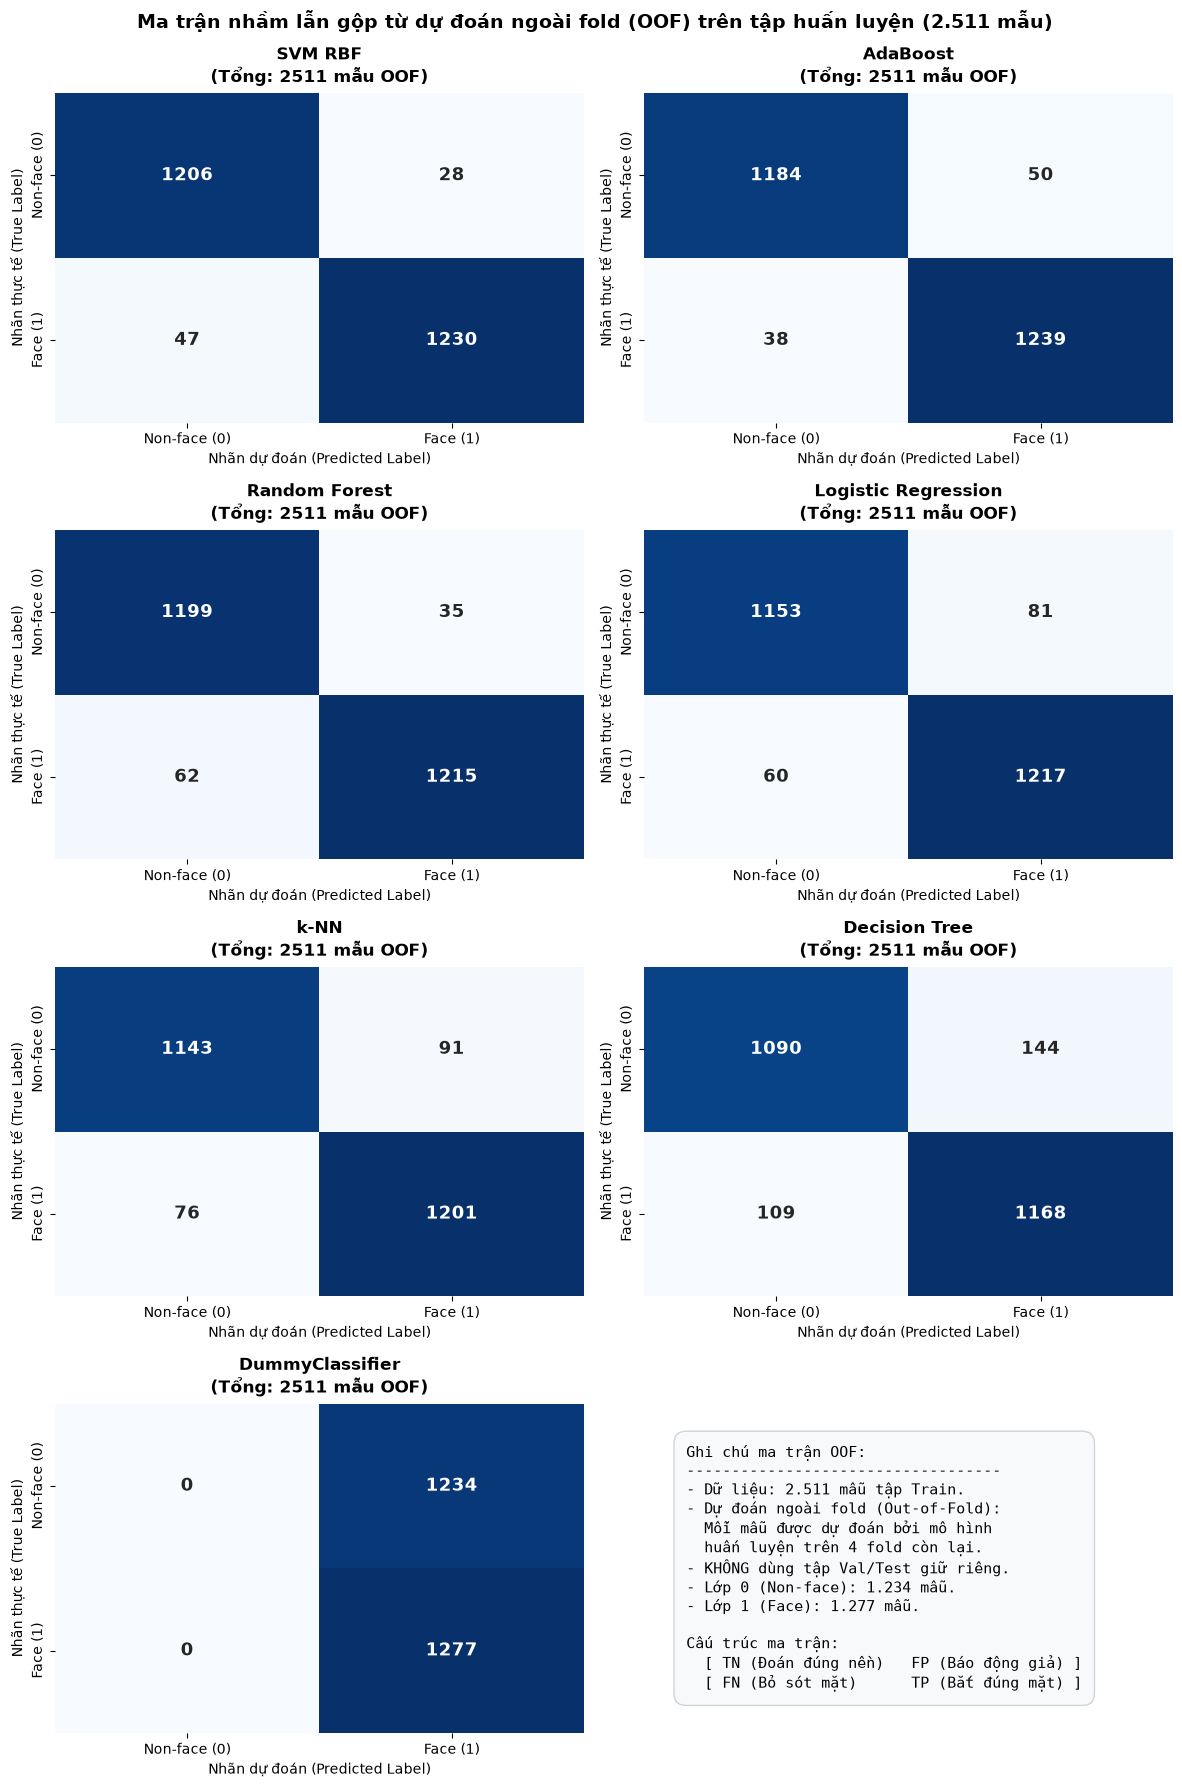

Đã lưu hình ma trận nhầm lẫn vào: reports\figures\week6_oof_confusion_matrices.png


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

models_order = ["SVM RBF", "AdaBoost", "Random Forest", "Logistic Regression", "k-NN", "Decision Tree", "DummyClassifier"]

# 1. Tính toán bảng ma trận nhầm lẫn gộp
cm_table_rows = []
for m in models_order:
    sub = df_oof[df_oof["model"] == m]
    tn, fp, fn, tp = confusion_matrix(sub["y_true"], sub["y_pred"], labels=[0, 1]).ravel()
    total = tn + fp + fn + tp
    assert total == 2511
    acc_pooled = (tp + tn) / total
    prec_pooled = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec_pooled = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1_pooled = 2 * prec_pooled * rec_pooled / (prec_pooled + rec_pooled) if (prec_pooled + rec_pooled) > 0 else 0
    fpr_pooled = fp / (fp + tn) if (fp + tn) > 0 else 0
    
    cm_table_rows.append({
        "model": m,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "total_samples": total,
        "pooled_accuracy": round(acc_pooled, 4),
        "pooled_precision": round(prec_pooled, 4),
        "pooled_recall": round(rec_pooled, 4),
        "pooled_f1": round(f1_pooled, 4),
        "pooled_fpr": round(fpr_pooled, 4)
    })

df_cm_table = pd.DataFrame(cm_table_rows)
cm_csv_path = TABLES_DIR / "week6_oof_confusion_matrices.csv"
df_cm_table.to_csv(cm_csv_path, index=False, encoding="utf-8-sig")
print(f"Đã lưu bảng ma trận nhầm lẫn gộp vào: {cm_csv_path}")
display(df_cm_table)

# 2. Vẽ đồ thị ma trận nhầm lẫn tổng hợp 7 mô hình bố cục 4 hàng x 2 cột (phù hợp tài liệu A4)
fig, axes = plt.subplots(4, 2, figsize=(12, 18))
axes = axes.flatten()

for idx, m in enumerate(models_order):
    ax = axes[idx]
    sub = df_oof[df_oof["model"] == m]
    cm = confusion_matrix(sub["y_true"], sub["y_pred"], labels=[0, 1])
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Non-face (0)", "Face (1)"],
                yticklabels=["Non-face (0)", "Face (1)"],
                annot_kws={"size": 13, "weight": "bold"})
    ax.set_title(f"{m}\n(Tổng: {len(sub)} mẫu OOF)", fontsize=12, fontweight="bold", pad=8)
    ax.set_ylabel("Nhãn thực tế (True Label)", fontsize=10)
    ax.set_xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10)

# Ô thứ 8: Hộp chú thích diễn giải
axes[7].axis("off")
summary_text = (
    "Ghi chú ma trận OOF:\n"
    "-----------------------------------\n"
    "- Dữ liệu: 2.511 mẫu tập Train.\n"
    "- Dự đoán ngoài fold (Out-of-Fold):\n"
    "  Mỗi mẫu được dự đoán bởi mô hình\n"
    "  huấn luyện trên 4 fold còn lại.\n"
    "- KHÔNG dùng tập Val/Test giữ riêng.\n"
    "- Lớp 0 (Non-face): 1.234 mẫu.\n"
    "- Lớp 1 (Face): 1.277 mẫu.\n\n"
    "Cấu trúc ma trận:\n"
    "  [ TN (Đoán đúng nền)   FP (Báo động giả) ]\n"
    "  [ FN (Bỏ sót mặt)      TP (Bắt đúng mặt) ]"
)
axes[7].text(0.08, 0.5, summary_text, fontsize=11, family="monospace", verticalalignment="center",
             bbox=dict(boxstyle="round,pad=0.8", facecolor="#f8f9fa", edgecolor="#ced4da"))

fig.suptitle("Ma trận nhầm lẫn gộp từ dự đoán ngoài fold (OOF) trên tập huấn luyện (2.511 mẫu)",
             fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
cm_fig_path = FIGURES_DIR / "week6_oof_confusion_matrices.png"
plt.savefig(cm_fig_path, dpi=300)
plt.show()
print(f"Đã lưu hình ma trận nhầm lẫn vào: {cm_fig_path}")

### 3. Trực quan hóa đường cong ROC trung bình qua 5 fold (Mean ROC Curves)

Vẽ đường cong ROC trung bình (Mean ROC) kèm dải độ lệch chuẩn ($\pm 1\,\text{std}$) cho cả 7 mô hình:
- Trục tung: Độ nhạy / Tỷ lệ phát hiện đúng ($\text{TPR} = \text{Recall}$).
- Trục hoành: Tỷ lệ báo động giả ($\text{FPR}$).
- Khung (a): Toàn cảnh dải $\text{FPR} \in [0, 1]$.
- Khung (b): Phóng to vùng $\text{FPR} \in [0, 0{,}15]$ và $\text{TPR} \in [0{,}80, 1{,}01]$ để phân tích chi tiết vùng làm việc thực tế với báo động giả thấp.
- Lưu hình ảnh tại `reports/figures/week6_cv_mean_roc.png` ($\ge 300$ dpi) và các điểm nội suy tại `reports/tables/week6_cv_roc_points.csv`.

Đã lưu bảng điểm nội suy ROC (3500 dòng) vào: reports\tables\week6_cv_roc_points.csv


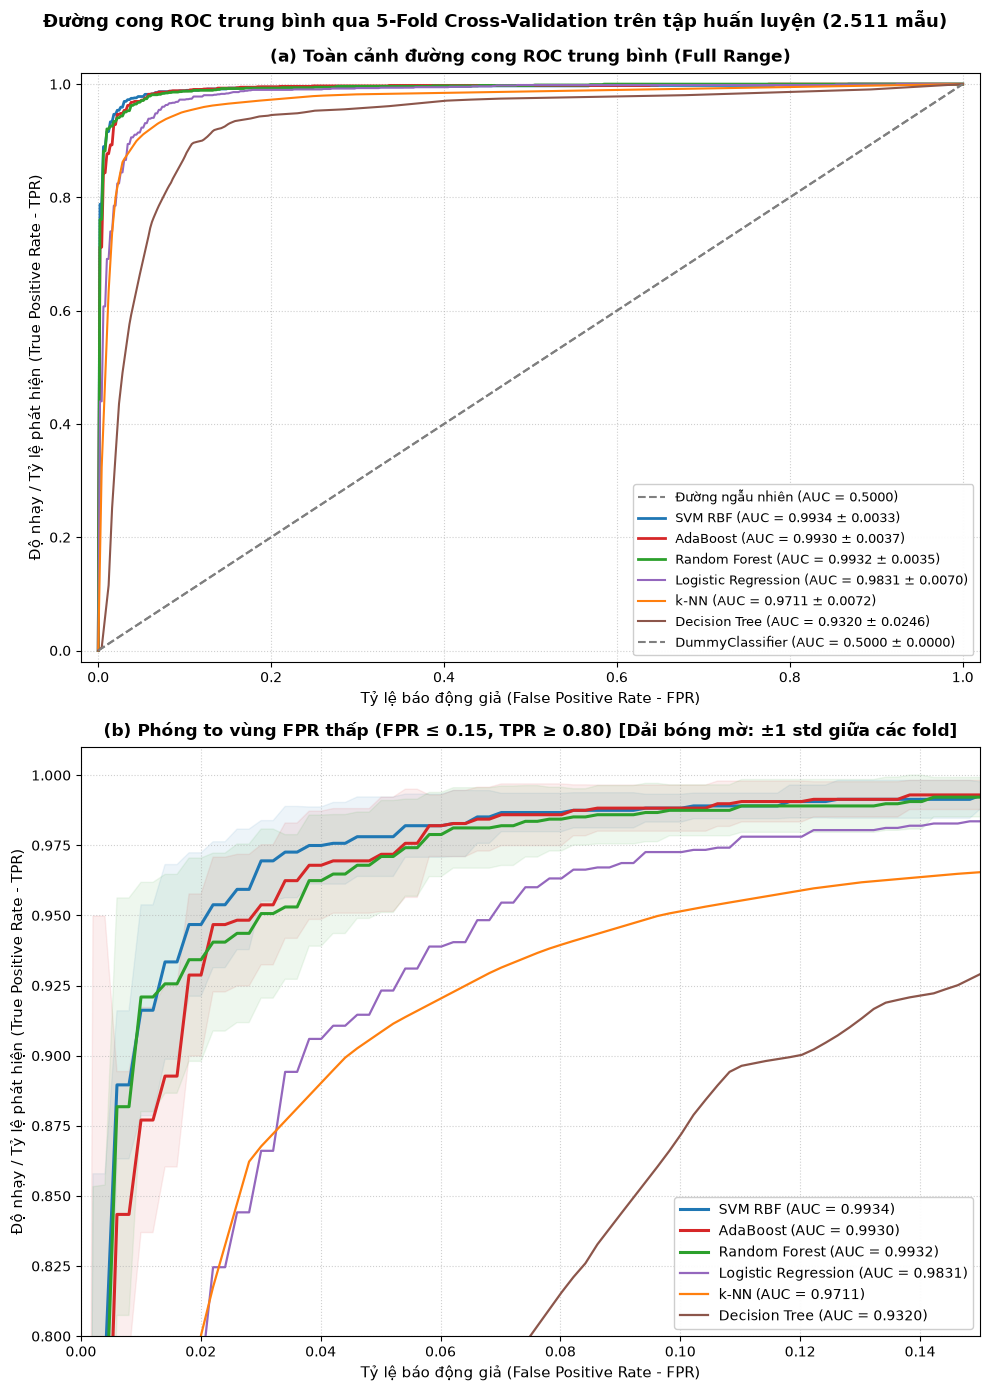

Đã lưu hình đường cong ROC vào: reports\figures\week6_cv_mean_roc.png


In [12]:
from sklearn.metrics import roc_curve, roc_auc_score

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

mean_fpr = np.linspace(0, 1, 500)
colors = {
    "SVM RBF": "#1f77b4",
    "AdaBoost": "#d62728",
    "Random Forest": "#2ca02c",
    "Logistic Regression": "#9467bd",
    "k-NN": "#ff7f0e",
    "Decision Tree": "#8c564b",
    "DummyClassifier": "#7f7f7f"
}

roc_points_rows = []
model_curves = {}

for m in models_order:
    tprs, aucs = [], []
    for f in range(1, 6):
        sub = df_oof[(df_oof["model"] == m) & (df_oof["cv_fold"] == f)]
        y_true = sub["y_true"].to_numpy()
        score = sub["score"].to_numpy()
        if len(np.unique(score)) == 1:
            fpr, tpr = np.array([0.0, 1.0]), np.array([0.0, 1.0])
            auc = 0.5
        else:
            fpr, tpr, _ = roc_curve(y_true, score)
            auc = roc_auc_score(y_true, score)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(auc)
        
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    std_tpr = np.std(tprs, axis=0, ddof=0)
    mean_auc = np.mean(aucs)
    std_auc = np.std(aucs, ddof=0)
    
    # Đối soát với bảng CV summary
    sum_row = df_cv_summary[(df_cv_summary["model"] == m) & (df_cv_summary["split"] == "validation_cv") & (df_cv_summary["metric"] == "roc_auc")].iloc[0]
    assert np.isclose(mean_auc, sum_row["mean"], atol=1e-5)
    assert np.isclose(std_auc, sum_row["std"], atol=1e-5)
    
    model_curves[m] = {
        "mean_tpr": mean_tpr,
        "std_tpr": std_tpr,
        "mean_auc": mean_auc,
        "std_auc": std_auc
    }
    
    for f_val, t_val, s_val in zip(mean_fpr, mean_tpr, std_tpr):
        roc_points_rows.append({
            "model": m,
            "fpr": round(float(f_val), 6),
            "mean_tpr": round(float(t_val), 6),
            "std_tpr": round(float(s_val), 6)
        })

df_roc_points = pd.DataFrame(roc_points_rows)
roc_csv_path = TABLES_DIR / "week6_cv_roc_points.csv"
df_roc_points.to_csv(roc_csv_path, index=False, encoding="utf-8-sig")
print(f"Đã lưu bảng điểm nội suy ROC ({len(df_roc_points)} dòng) vào: {roc_csv_path}")

# Vẽ đồ thị ROC 2 khung nhìn xếp dọc (phù hợp trang tài liệu A4)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 14))

# Khung 1: Toàn dải FPR [0, 1]
ax1.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1.5, label="Đường ngẫu nhiên (AUC = 0.5000)")

for m in models_order:
    data = model_curves[m]
    label_text = f"{m} (AUC = {data['mean_auc']:.4f} ± {data['std_auc']:.4f})"
    linestyle = "--" if m == "DummyClassifier" else "-"
    lw = 2.0 if m in ["SVM RBF", "AdaBoost", "Random Forest"] else 1.5
    ax1.plot(mean_fpr, data["mean_tpr"], color=colors[m], lw=lw, linestyle=linestyle, label=label_text)

ax1.set_xlim([-0.02, 1.02])
ax1.set_ylim([-0.02, 1.02])
ax1.set_xlabel("Tỷ lệ báo động giả (False Positive Rate - FPR)", fontsize=11)
ax1.set_ylabel("Độ nhạy / Tỷ lệ phát hiện (True Positive Rate - TPR)", fontsize=11)
ax1.set_title("(a) Toàn cảnh đường cong ROC trung bình (Full Range)", fontsize=12, fontweight="bold", pad=8)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right", fontsize=9.5, framealpha=0.95)

# Khung 2: Phóng to vùng FPR thấp [0, 0.15], TPR [0.80, 1.01]
for m in models_order:
    if m == "DummyClassifier":
        continue
    data = model_curves[m]
    lw = 2.2 if m in ["SVM RBF", "AdaBoost", "Random Forest"] else 1.6
    ax2.plot(mean_fpr, data["mean_tpr"], color=colors[m], lw=lw,
             label=f"{m} (AUC = {data['mean_auc']:.4f})")
    if m in ["SVM RBF", "AdaBoost", "Random Forest"]:
        tpr_upper = np.minimum(data["mean_tpr"] + data["std_tpr"], 1.0)
        tpr_lower = np.maximum(data["mean_tpr"] - data["std_tpr"], 0.0)
        ax2.fill_between(mean_fpr, tpr_lower, tpr_upper, color=colors[m], alpha=0.08)

ax2.set_xlim([0.0, 0.15])
ax2.set_ylim([0.80, 1.01])
ax2.set_xlabel("Tỷ lệ báo động giả (False Positive Rate - FPR)", fontsize=11)
ax2.set_ylabel("Độ nhạy / Tỷ lệ phát hiện (True Positive Rate - TPR)", fontsize=11)
ax2.set_title("(b) Phóng to vùng FPR thấp (FPR ≤ 0.15, TPR ≥ 0.80) [Dải bóng mờ: ±1 std giữa các fold]", fontsize=12, fontweight="bold", pad=8)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower right", fontsize=10, framealpha=0.95)

fig.suptitle("Đường cong ROC trung bình qua 5-Fold Cross-Validation trên tập huấn luyện (2.511 mẫu)",
             fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
roc_fig_path = FIGURES_DIR / "week6_cv_mean_roc.png"
plt.savefig(roc_fig_path, dpi=300)
plt.show()
print(f"Đã lưu hình đường cong ROC vào: {roc_fig_path}")

### 4. Phân tích kết quả trực quan hóa và ý nghĩa thực tiễn

#### 1. Phân tích ma trận nhầm lẫn gộp (Pooled OOF Confusion Matrix)
- **Kiểm soát báo động giả (False Positives - FP):**
  Trong bài toán phát hiện khuôn mặt thực tế, một bức ảnh thường chứa hàng nghìn đến hàng vạn vùng nền (cửa sổ không phải mặt), do đó việc khống chế số lượng báo động giả là yếu tố then chốt:
  + **SVM (kernel RBF)** kiểm soát báo động giả tốt nhất với chỉ $FP = 28$ trên $1.234$ mẫu nền gộp ($\text{FPR} = 2{,}27\%$, $\text{Precision} = 97{,}77\%$), đồng thời dự đoán đúng $TN = 1.206$ mẫu nền.
  + **Random Forest** đạt vị trí thứ hai với $FP = 35$ ($\text{FPR} = 2{,}84\%$, $\text{Precision} = 97{,}20\%$), $TN = 1.199$.
  + **AdaBoost (Decision Stump)** ghi nhận $FP = 50$ ($\text{FPR} = 4{,}05\%$, $\text{Precision} = 96{,}12\%$), $TN = 1.184$.
  + **Logistic Regression** ($FP = 81$), **k-NN** ($FP = 91$) và **Decision Tree** ($FP = 144$) có số lượng báo động giả cao hơn đáng kể.
  + **DummyClassifier** đoán toàn bộ lớp dương tính nên báo động giả tuyệt đối $FP = 1.234$ ($\text{FPR} = 100\%$), không nhận diện được bất kỳ mẫu nền nào ($TN = 0$).

- **Khả năng bao phủ và tránh bỏ sót khuôn mặt (False Negatives - FN):**
  + **AdaBoost** bỏ sót ít khuôn mặt nhất trong sáu thuật toán học máy với chỉ $FN = 38$ trên $1.277$ khuôn mặt ($\text{Recall} = 97{,}02\%$), bắt đúng $TP = 1.239$ mặt.
  + **SVM RBF** bỏ sót $FN = 47$ khuôn mặt ($\text{Recall} = 96{,}32\%$), $TP = 1.230$.
  + **Logistic Regression** bỏ sót $FN = 60$ ($TP = 1.217$), **Random Forest** bỏ sót $FN = 62$ ($TP = 1.215$), **k-NN** bỏ sót $FN = 76$ ($TP = 1.201$), và **Decision Tree** bỏ sót $FN = 109$ ($TP = 1.168$).
  + DummyClassifier tuy có $FN = 0$ ($TP = 1.277$, $\text{Recall} = 100\%$) nhưng giá trị này không mang ý nghĩa thực tiễn vì đánh đổi bằng việc gán nhãn toàn bộ ảnh thành mặt.

- **So sánh AdaBoost và SVM RBF:**
  + AdaBoost thiên về tối ưu độ nhạy (ưu tiên bắt trọn khuôn mặt, $FN$ thấp hơn), trong khi SVM RBF thiên về kiểm soát độ chính xác và giảm thiểu báo động giả ($FP$ thấp nhất).
  + Trong các bước tiếp theo (Tuần 7), việc điều chỉnh ngưỡng quyết định (threshold tuning) sẽ giúp dịch chuyển sự đánh đổi giữa $FP$ và $FN$ tùy theo yêu cầu cụ thể của bài toán.

#### 2. Phân tích đường cong ROC trung bình và dải biến thiên
- **Năng lực phân biệt tổng thể (Toàn dải ROC):**
  + Cả ba mô hình **SVM RBF** ($\text{AUC} = 0{,}9934 \pm 0{,}0033$), **Random Forest** ($\text{AUC} = 0{,}9932 \pm 0{,}0035$), và **AdaBoost** ($\text{AUC} = 0{,}9930 \pm 0{,}0037$) đều có đường cong ROC tiệm cận góc trên bên trái, vượt xa đường chéo ngẫu nhiên của DummyClassifier ($\text{AUC} = 0{,}5000$).
  + Dải bóng mờ biểu diễn độ lệch chuẩn ($\pm 1\,\text{std}$) mô tả mức độ biến thiên thực nghiệm giữa 5 fold kiểm định, không phải là khoảng tin cậy thống kê (confidence interval) hay bằng chứng bảo đảm tuyệt đối về độ ổn định.

- **Vùng làm việc thực tế (Phóng to dải FPR thấp $\le 0{,}15$):**
  + Ở vùng $\text{FPR} \le 0{,}02$, **SVM RBF** và **Random Forest** nhanh chóng vươn lên đạt $\text{TPR} \ge 90\%$, cho thấy khả năng phân tách sắc nét giữa các phân bố mẫu với ít cảnh báo giả.
  + **AdaBoost** bám rất sát và có độ dốc ban đầu lớn, phù hợp với cơ chế tập hợp các bộ phân loại yếu tập trung vào các mẫu khó.
  + **Decision Tree đơn lẻ** tụt lại phía sau với đường cong có nhiều đoạn gấp khúc và diện tích $\text{AUC} = 0{,}9320 \pm 0{,}0246$, phản ánh hạn chế của một cấu trúc cây rời rạc trong việc sinh ra điểm số xác suất liên tục.

#### 3. Giới hạn phương pháp luận và bước đi tiếp theo
- Dự đoán ngoài fold (OOF) vẫn thuộc tập train tổng thể ($2.511$ mẫu), nhưng mỗi dự đoán được tạo ra ngoài phần huấn luyện của fold tương ứng (huấn luyện trên 4 fold còn lại để suy luận).
- Tập Validation giữ riêng ($540$ mẫu) và tập Test ($538$ mẫu) tiếp tục được bảo vệ nguyên vẹn để phục vụ lựa chọn cấu hình/ngưỡng tối ưu và đánh giá độc lập sau cùng.

---
# Tiêu chí 7 — Phân tích mẫu/nhóm dự đoán sai và đối chiếu kết quả huấn luyện với kiểm định

### 1. Kiểm tra tính toàn vẹn và thứ tự dữ liệu ảnh gốc (images_24x24.npy)

Để phục vụ phân tích trực quan các trường hợp phân loại sai, tệp ảnh gốc `images_24x24.npy` được nạp và thẩm định nghiêm ngặt:
- Xác nhận kích thước đúng $(3.589, 24, 24)$ và kiểu dữ liệu `uint8`.
- Đối chiếu mã băm SHA-256 của từng ảnh với cột `sha256` trong `metadata.csv` bằng hàm `hashlib.sha256(np.ascontiguousarray(image).tobytes()).hexdigest()`.
- Sử dụng trường `global_row_index` trong bảng dự đoán OOF để ánh xạ chính xác đến từng ảnh mẫu gốc. Nếu phát hiện bất kỳ sự sai lệch nào về mã băm, nhãn hay định danh mẫu, quy trình sẽ dừng ngay lập tức.

In [13]:
import hashlib

# 1. Nạp và kiểm tra tệp ảnh gốc 24x24
images_path = DATA_DIR / "images_24x24.npy"
assert images_path.exists(), f"Không tìm thấy tệp ảnh: {images_path.resolve()}"

images_24x24 = np.load(images_path)
print(f"Kích thước tệp ảnh: {images_24x24.shape}, kiểu dữ liệu: {images_24x24.dtype}")

assert images_24x24.shape == (3589, 24, 24), f"Kích thước ảnh không đúng: {images_24x24.shape}"
assert images_24x24.dtype == np.uint8, f"Kiểu dữ liệu ảnh không phải uint8: {images_24x24.dtype}"

# 2. Đối chiếu mã băm SHA-256 từng ảnh với metadata
print("Đang đối chiếu mã băm SHA-256 của 3.589 ảnh với cột sha256 trong metadata...")
hash_mismatches = 0
for idx in range(len(images_24x24)):
    img_bytes = np.ascontiguousarray(images_24x24[idx]).tobytes()
    img_hash = hashlib.sha256(img_bytes).hexdigest()
    if img_hash != metadata.loc[idx, "sha256"]:
        hash_mismatches += 1

assert hash_mismatches == 0, f"Phát hiện {hash_mismatches} ảnh không khớp mã băm SHA-256 với metadata!"
print("Thẩm định thành công: 100% (3.589/3.589) ảnh khớp chính xác mã băm SHA-256 với metadata.")

# 3. Kiểm tra tính toàn vẹn của ánh xạ global_row_index trên TOÀN BỘ dòng của bảng OOF
print(f"Kiểm tra tính nhất quán của toàn bộ {len(df_oof)} dòng OOF với metadata...")
assert (df_oof["y_true"].values == metadata.loc[df_oof["global_row_index"], "label"].values).all(), "Phát hiện nhãn không khớp giữa OOF và metadata!"
assert (df_oof["source_id"].values == metadata.loc[df_oof["global_row_index"], "source_id"].values).all(), "Phát hiện source_id không khớp giữa OOF và metadata!"
assert (df_oof["group"].values == metadata.loc[df_oof["global_row_index"], "group"].values).all(), "Phát hiện group không khớp giữa OOF và metadata!"
print(f"Thẩm định thành công: Toàn bộ {len(df_oof)} dòng OOF khớp chính xác 100% với metadata.")
print("Ánh xạ global_row_index hoàn toàn chính xác và an toàn để trích xuất ảnh.")

Kích thước tệp ảnh: (3589, 24, 24), kiểu dữ liệu: uint8
Đang đối chiếu mã băm SHA-256 của 3.589 ảnh với cột sha256 trong metadata...
Thẩm định thành công: 100% (3.589/3.589) ảnh khớp chính xác mã băm SHA-256 với metadata.
Kiểm tra tính nhất quán của toàn bộ 17577 dòng OOF với metadata...
Thẩm định thành công: Toàn bộ 17577 dòng OOF khớp chính xác 100% với metadata.
Ánh xạ global_row_index hoàn toàn chính xác và an toàn để trích xuất ảnh.


### 2. Trích xuất, phân loại lỗi và tổng hợp theo nhóm cho sáu mô hình học máy

Tiến hành rà soát toàn bộ dự đoán ngoài fold (OOF) của sáu mô hình học máy để phân loại hai dạng lỗi:
- **False Positive (FP - Báo động giả):** Nhãn thực tế là nền ($y_{\text{true}} = 0$) nhưng mô hình dự đoán là mặt ($y_{\text{pred}} = 1$).
- **False Negative (FN - Bỏ sót mặt):** Nhãn thực tế là mặt ($y_{\text{true}} = 1$) nhưng mô hình dự đoán là nền ($y_{\text{pred}} = 0$).

Toàn bộ các mẫu sai được lưu vào `week6_error_samples.csv` và đối soát chặt chẽ với ma trận nhầm lẫn gộp. Đồng thời, lỗi được tổng hợp theo từng nhóm (`group`) để tính tỷ lệ lỗi khách quan (mẫu số là tổng số mẫu OOF thực tế của nhóm đó trong tập huấn luyện), lưu vào `week6_error_groups.csv`.

In [14]:
six_ml_models = ["SVM RBF", "AdaBoost", "Random Forest", "Logistic Regression", "k-NN", "Decision Tree"]

# 1. Trích xuất toàn bộ mẫu dự đoán sai của 6 mô hình học máy
err_samples_records = []
for m in six_ml_models:
    sub_m = df_oof[df_oof["model"] == m].copy()
    fp_mask = (sub_m["y_true"] == 0) & (sub_m["y_pred"] == 1)
    fn_mask = (sub_m["y_true"] == 1) & (sub_m["y_pred"] == 0)
    
    fp_df = sub_m[fp_mask].copy()
    fp_df["error_type"] = "FP"
    
    fn_df = sub_m[fn_mask].copy()
    fn_df["error_type"] = "FN"
    
    # Đối soát với bảng ma trận nhầm lẫn OOF đã lưu
    cm_row = df_cm_table[df_cm_table["model"] == m].iloc[0]
    assert len(fp_df) == cm_row["FP"], f"Số lượng FP của {m} không khớp: {len(fp_df)} vs {cm_row['FP']}"
    assert len(fn_df) == cm_row["FN"], f"Số lượng FN của {m} không khớp: {len(fn_df)} vs {cm_row['FN']}"
    
    err_samples_records.append(fp_df)
    err_samples_records.append(fn_df)

df_error_samples = pd.concat(err_samples_records, axis=0).reset_index(drop=True)
err_cols = [
    "model", "cv_fold", "train_row_index", "global_row_index",
    "source_id", "group", "y_true", "y_pred", "score", "score_method", "error_type"
]
df_error_samples = df_error_samples[err_cols]
error_samples_path = TABLES_DIR / "week6_error_samples.csv"
df_error_samples.to_csv(error_samples_path, index=False, encoding="utf-8-sig")
print(f"Đã lưu bảng danh sách mẫu lỗi ({len(df_error_samples)} dòng) vào: {error_samples_path}")

# Thống kê tổng số lỗi theo từng mô hình
print("\nThống kê số lượng lỗi theo mô hình (khớp 100% với ma trận nhầm lẫn):")
for m in six_ml_models:
    sub = df_error_samples[df_error_samples["model"] == m]
    n_fp = (sub["error_type"] == "FP").sum()
    n_fn = (sub["error_type"] == "FN").sum()
    print(f"  + {m:20s}: FP = {n_fp:3d}, FN = {n_fn:3d}, Tổng lỗi = {n_fp + n_fn:3d}")

# 2. Tổng hợp lỗi theo nhóm (group)
err_groups_records = []
for m in six_ml_models:
    sub_all = df_oof[df_oof["model"] == m].copy()
    sub_all["is_error"] = (sub_all["y_true"] != sub_all["y_pred"]).astype(int)
    sub_all["is_fp"] = ((sub_all["y_true"] == 0) & (sub_all["y_pred"] == 1)).astype(int)
    sub_all["is_fn"] = ((sub_all["y_true"] == 1) & (sub_all["y_pred"] == 0)).astype(int)
    
    grp = sub_all.groupby("group").agg(
        group_label=("y_true", "first"),
        total_samples=("y_true", "count"),
        num_errors=("is_error", "sum"),
        num_fp=("is_fp", "sum"),
        num_fn=("is_fn", "sum")
    ).reset_index()
    
    grp["model"] = m
    grp["error_rate"] = (grp["num_errors"] / grp["total_samples"]).round(4)
    grp = grp[["model", "group", "group_label", "total_samples", "num_errors", "error_rate", "num_fp", "num_fn"]]
    err_groups_records.append(grp)

df_error_groups = pd.concat(err_groups_records, axis=0).reset_index(drop=True)
error_groups_path = TABLES_DIR / "week6_error_groups.csv"
df_error_groups.to_csv(error_groups_path, index=False, encoding="utf-8-sig")
print(f"\nĐã lưu bảng tổng hợp lỗi theo nhóm ({len(df_error_groups)} dòng) vào: {error_groups_path}")

# 3. Trình bày các nhóm có nhiều lỗi của AdaBoost và SVM RBF
for m in ["AdaBoost", "SVM RBF"]:
    sub_g = df_error_groups[(df_error_groups["model"] == m) & (df_error_groups["num_errors"] > 0)].copy()
    sub_g_sorted = sub_g.sort_values(by=["num_errors", "total_samples"], ascending=[False, False])
    print(f"\nBẢNG CÁC NHÓM CÓ LỖI NHIỀU NHẤT CỦA {m} (Hiển thị nhóm có num_errors >= 2):")
    display(sub_g_sorted[sub_g_sorted["num_errors"] >= 2].reset_index(drop=True))

Đã lưu bảng danh sách mẫu lỗi (821 dòng) vào: reports\tables\week6_error_samples.csv

Thống kê số lượng lỗi theo mô hình (khớp 100% với ma trận nhầm lẫn):
  + SVM RBF             : FP =  28, FN =  47, Tổng lỗi =  75
  + AdaBoost            : FP =  50, FN =  38, Tổng lỗi =  88
  + Random Forest       : FP =  35, FN =  62, Tổng lỗi =  97
  + Logistic Regression : FP =  81, FN =  60, Tổng lỗi = 141
  + k-NN                : FP =  91, FN =  76, Tổng lỗi = 167
  + Decision Tree       : FP = 144, FN = 109, Tổng lỗi = 253

Đã lưu bảng tổng hợp lỗi theo nhóm (6768 dòng) vào: reports\tables\week6_error_groups.csv



BẢNG CÁC NHÓM CÓ LỖI NHIỀU NHẤT CỦA AdaBoost (Hiển thị nhóm có num_errors >= 2):


,model,group,group_label,total_samples,num_errors,error_rate,num_fp,num_fn
0,AdaBoost,caltech_image:Caltech101/BACKGROUND_Google/ima...,0,5,2,0.4000,2,0
1,AdaBoost,caltech_image:Caltech101/BACKGROUND_Google/ima...,0,4,2,0.5000,2,0
2,AdaBoost,lfw_person:2058,1,3,2,0.6667,0,2
3,AdaBoost,lfw_person:2750,1,2,2,1.0000,0,2



BẢNG CÁC NHÓM CÓ LỖI NHIỀU NHẤT CỦA SVM RBF (Hiển thị nhóm có num_errors >= 2):


,model,group,group_label,total_samples,num_errors,error_rate,num_fp,num_fn
0,SVM RBF,caltech_image:Caltech101/BACKGROUND_Google/ima...,0,5,2,0.4000,2,0
1,SVM RBF,caltech_image:Caltech101/BACKGROUND_Google/ima...,0,5,2,0.4000,2,0
2,SVM RBF,lfw_person:5354,1,5,2,0.4000,0,2
3,SVM RBF,lfw_person:2058,1,3,2,0.6667,0,2
4,SVM RBF,lfw_person:291,1,3,2,0.6667,0,2
5,SVM RBF,lfw_person:2750,1,2,2,1.0000,0,2


### 3. Trực quan hóa mẫu ảnh dự đoán sai tiêu biểu (FP và FN) của AdaBoost và SVM RBF

Để phân tích bản chất thị giác của các lỗi phân loại, với mỗi mô hình trong hai thuật toán trọng tâm (**AdaBoost** và **SVM RBF**):
- Chọn tối đa $8$ mẫu FP và $8$ mẫu FN một cách tái lập với `random_state=42`.
- Ưu tiên chọn từ các nhóm khác nhau để đảm bảo tính đa dạng của trường hợp lỗi.
- Trình bày dạng lưới $4 \times 4$: hai hàng đầu là $8$ mẫu FP (ảnh nền bị nhận nhầm thành mặt), hai hàng sau là $8$ mẫu FN (khuôn mặt bị nhận nhầm thành nền).
- Hiển thị trực tiếp ảnh xám gốc $24 \times 24$, tên loại lỗi và mã chỉ số toàn cục `global_row_index`. Toàn bộ thông số chi tiết (độ sáng trung bình, độ tương phản, nguồn ảnh gốc) được lưu vào `week6_error_examples.csv`.

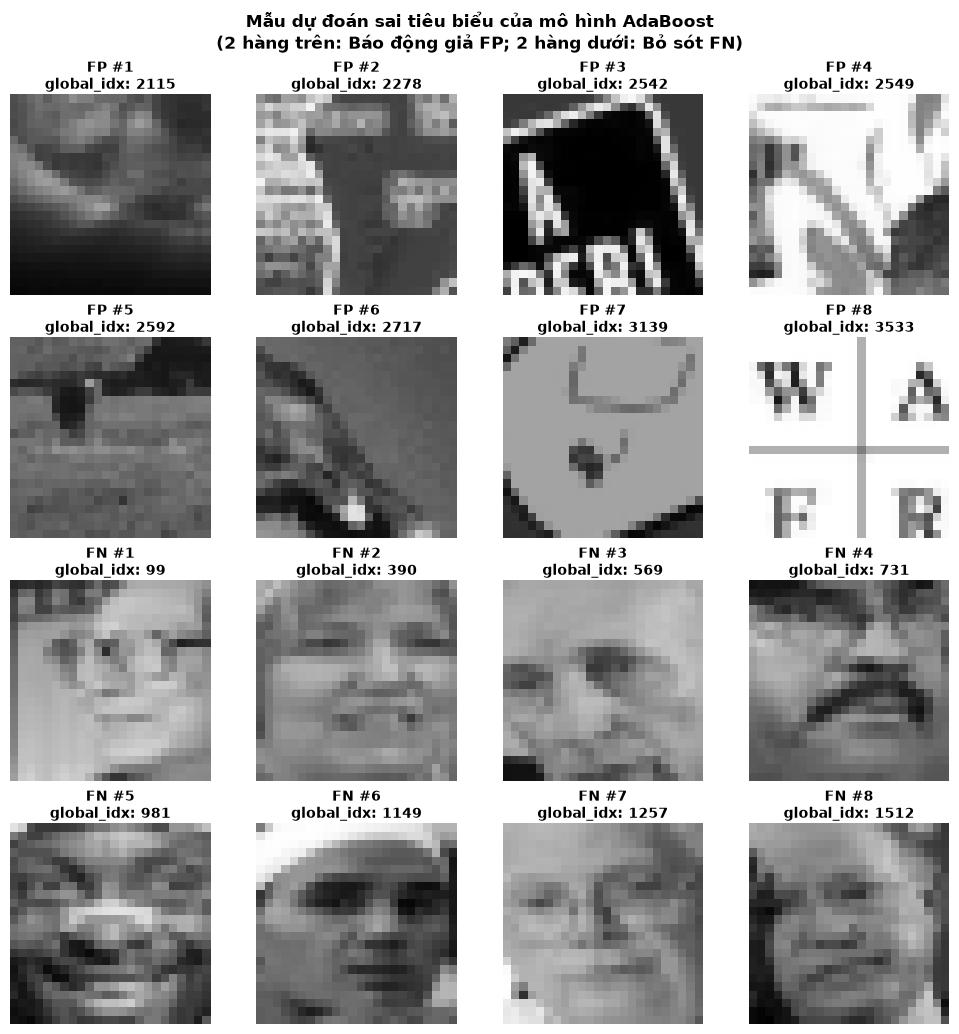

Đã lưu biểu đồ mẫu lỗi vào: reports\figures\week6_errors_adaboost.png


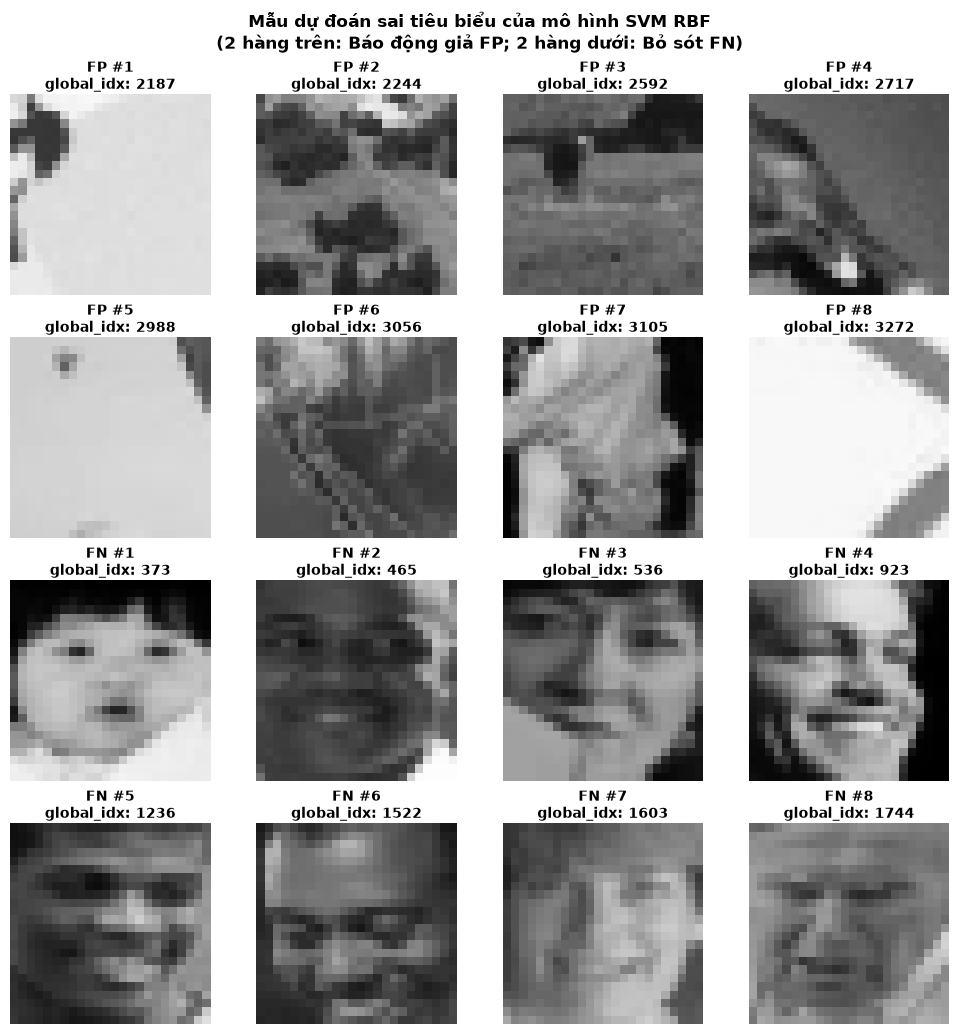

Đã lưu biểu đồ mẫu lỗi vào: reports\figures\week6_errors_svm_rbf.png
Đã lưu bảng 32 mẫu lỗi minh họa vào: reports\tables\week6_error_examples.csv


,model,error_type,example_id,global_row_index,mean_gray,std_gray,source
0,AdaBoost,FP,FP_1,2115,68.27,37.58,Caltech đã duyệt
1,AdaBoost,FP,FP_2,2278,112.76,52.61,Caltech đã duyệt
2,AdaBoost,FP,FP_3,2542,68.24,82.04,Caltech đã duyệt
3,AdaBoost,FP,FP_4,2549,185.92,68.69,Caltech đã duyệt
4,AdaBoost,FP,FP_5,2592,89.98,29.90,Caltech đã duyệt
5,AdaBoost,FP,FP_6,2717,87.28,30.21,Caltech đã duyệt
6,AdaBoost,FP,FP_7,3139,144.77,39.40,Caltech đã duyệt
7,AdaBoost,FP,FP_8,3533,224.89,52.95,Caltech đã duyệt
8,AdaBoost,FN,FN_1,99,156.48,38.41,LFW
9,AdaBoost,FN,FN_2,390,128.93,24.52,LFW


In [15]:
def select_error_examples(df_err_type, n_samples=8, random_state=42):
    rng = np.random.RandomState(random_state)
    df_shuffled = df_err_type.sample(frac=1.0, random_state=rng).reset_index(drop=True)
    df_unique_groups = df_shuffled.drop_duplicates(subset=["group"]).reset_index(drop=True)
    if len(df_unique_groups) >= n_samples:
        selected = df_unique_groups.iloc[:n_samples].copy()
    else:
        remainder = df_shuffled[~df_shuffled.index.isin(df_unique_groups.index)]
        needed = n_samples - len(df_unique_groups)
        selected = pd.concat([df_unique_groups, remainder.iloc[:needed]], axis=0)
    return selected.sort_values(by="global_row_index").reset_index(drop=True)

example_rows = []

for m, fig_name in [("AdaBoost", "week6_errors_adaboost.png"), ("SVM RBF", "week6_errors_svm_rbf.png")]:
    sub_m = df_error_samples[df_error_samples["model"] == m]
    fp_sub = sub_m[sub_m["error_type"] == "FP"]
    fn_sub = sub_m[sub_m["error_type"] == "FN"]
    
    sel_fp = select_error_examples(fp_sub, 8, random_state=42)
    sel_fn = select_error_examples(fn_sub, 8, random_state=42)
    
    fig, axes = plt.subplots(4, 4, figsize=(10, 10.5))
    
    # 2 hàng đầu: 8 mẫu FP
    for idx, row in sel_fp.iterrows():
        r = idx // 4
        c = idx % 4
        ax = axes[r, c]
        g_idx = int(row["global_row_index"])
        img = images_24x24[g_idx]
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"FP #{idx+1}\nglobal_idx: {g_idx}", fontsize=10, fontweight="bold", pad=4)
        ax.axis("off")
        
        m_meta = metadata.loc[g_idx]
        rec = row.to_dict()
        rec["example_id"] = f"FP_{idx+1}"
        rec["mean_gray"] = round(float(m_meta["mean_gray"]), 2)
        rec["std_gray"] = round(float(m_meta["std_gray"]), 2)
        rec["origin"] = m_meta["origin"]
        rec["source"] = m_meta["source"]
        example_rows.append(rec)
        
    # 2 hàng sau: 8 mẫu FN
    for idx, row in sel_fn.iterrows():
        r = 2 + (idx // 4)
        c = idx % 4
        ax = axes[r, c]
        g_idx = int(row["global_row_index"])
        img = images_24x24[g_idx]
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"FN #{idx+1}\nglobal_idx: {g_idx}", fontsize=10, fontweight="bold", pad=4)
        ax.axis("off")
        
        m_meta = metadata.loc[g_idx]
        rec = row.to_dict()
        rec["example_id"] = f"FN_{idx+1}"
        rec["mean_gray"] = round(float(m_meta["mean_gray"]), 2)
        rec["std_gray"] = round(float(m_meta["std_gray"]), 2)
        rec["origin"] = m_meta["origin"]
        rec["source"] = m_meta["source"]
        example_rows.append(rec)
        
    fig.suptitle(f"Mẫu dự đoán sai tiêu biểu của mô hình {m}\n(2 hàng trên: Báo động giả FP; 2 hàng dưới: Bỏ sót FN)",
                 fontsize=12, fontweight="bold", y=0.98)
    plt.tight_layout()
    err_fig_path = FIGURES_DIR / fig_name
    plt.savefig(err_fig_path, dpi=300)
    plt.show()
    print(f"Đã lưu biểu đồ mẫu lỗi vào: {err_fig_path}")

df_error_examples = pd.DataFrame(example_rows)
example_cols = [
    "model", "error_type", "example_id", "global_row_index", "train_row_index", "cv_fold",
    "source_id", "group", "y_true", "y_pred", "score", "score_method",
    "mean_gray", "std_gray", "origin", "source"
]
df_error_examples = df_error_examples[example_cols]
error_examples_path = TABLES_DIR / "week6_error_examples.csv"
df_error_examples.to_csv(error_examples_path, index=False, encoding="utf-8-sig")
print(f"Đã lưu bảng 32 mẫu lỗi minh họa vào: {error_examples_path}")
display(df_error_examples[["model", "error_type", "example_id", "global_row_index", "mean_gray", "std_gray", "source"]].head(16))

### 4. Đối chiếu kết quả Huấn luyện (Train) và Kiểm định (Validation CV)

Từ bảng tổng hợp kiểm định chéo `week6_models_cv_summary.csv`, trích xuất điểm số $F_1$ trên cả hai phần:
- $F_1$ tập huấn luyện (Train): trung bình $\pm$ độ lệch chuẩn qua 5 fold.
- $F_1$ phần kiểm định (Validation CV): trung bình $\pm$ độ lệch chuẩn qua 5 fold.
- Chênh lệch $\Delta F_1 = \text{mean}(F_{1,\text{train}}) - \text{mean}(F_{1,\text{val}})$ (tính trên giá trị dấu phẩy động đầy đủ trước khi làm tròn).

Bảng đối chiếu phản ánh đồng thời mức năng lực phân loại tuyệt đối và khoảng cách khái quát hóa giữa hai phần dữ liệu.

In [16]:
models_for_comp = ["SVM RBF", "AdaBoost", "Random Forest", "Logistic Regression", "k-NN", "Decision Tree", "DummyClassifier"]

comp_records = []
for m in models_for_comp:
    tr_row = df_cv_summary[(df_cv_summary["model"] == m) & (df_cv_summary["split"] == "train_cv") & (df_cv_summary["metric"] == "f1")].iloc[0]
    val_row = df_cv_summary[(df_cv_summary["model"] == m) & (df_cv_summary["split"] == "validation_cv") & (df_cv_summary["metric"] == "f1")].iloc[0]
    
    # Tính chênh lệch trước khi làm tròn
    delta_f1 = tr_row["mean"] - val_row["mean"]
    
    comp_records.append({
        "Mô hình": m,
        "F1 Train (Mean ± Std)": f"{tr_row['mean']:.4f} ± {tr_row['std']:.4f}",
        "F1 Val CV (Mean ± Std)": f"{val_row['mean']:.4f} ± {val_row['std']:.4f}",
        "Delta F1 (Train - Val)": f"{delta_f1:+.4f}",
        "_val_mean": val_row["mean"]
    })

df_train_val_comp = pd.DataFrame(comp_records).sort_values(by="_val_mean", ascending=False).drop(columns=["_val_mean"]).reset_index(drop=True)
print("\nBẢNG ĐỐI CHIẾU HIỆU NĂNG HUẤN LUYỆN VÀ KIỂM ĐỊNH (F1-SCORE):")
display(df_train_val_comp)


BẢNG ĐỐI CHIẾU HIỆU NĂNG HUẤN LUYỆN VÀ KIỂM ĐỊNH (F1-SCORE):


,Mô hình,F1 Train (Mean ± Std),F1 Val CV (Mean ± Std),Delta F1 (Train - Val)
0,SVM RBF,0.9884 ± 0.0011,0.9703 ± 0.0093,+0.0181
1,AdaBoost,0.9936 ± 0.0015,0.9656 ± 0.0116,+0.0280
2,Random Forest,0.9997 ± 0.0002,0.9616 ± 0.0110,+0.0381
3,Logistic Regression,0.9598 ± 0.0023,0.9453 ± 0.0100,+0.0145
4,k-NN,0.9561 ± 0.0008,0.9350 ± 0.0099,+0.0211
5,Decision Tree,0.9629 ± 0.0039,0.9024 ± 0.0185,+0.0606
6,DummyClassifier,0.6742 ± 0.0003,0.6742 ± 0.0012,-0.0000


### 5. Phân tích kết quả chuyên sâu, thảo luận đặc trưng và giới hạn phương pháp luận

#### 1. Phân tích đối chiếu Huấn luyện và Kiểm định (Train vs Validation CV)
- **Đánh giá đa chiều kết hợp mức điểm và độ chênh lệch:**
  Khi xem xét hiện tượng quá khớp, không thể chỉ nhìn vào một độ chênh lệch nhỏ ($\Delta F_1$) để kết luận mô hình hoạt động tốt mà bắt buộc phải phân tích đồng thời cả mức điểm kiểm định đạt được:
  + **DummyClassifier** có $\Delta F_1 = -0{,}0000$ (khoảng cách bằng không do không học từ đặc trưng ảnh), nhưng mức điểm kiểm định chỉ đạt $F_1 = 0{,}6742$ với tỷ lệ báo động giả tuyệt đối $\text{FPR} = 1{,}0000$ ($100\%$). Do đó, chênh lệch bằng 0 hoàn toàn không chứng minh mô hình có tính khái quát hóa hữu ích.
  + **Logistic Regression** duy trì khoảng cách rất hẹp $\Delta F_1 = +0{,}0145$, nhưng điểm kiểm định dừng ở $F_1 = 0{,}9453$, thấp hơn đáng kể so với SVM RBF và AdaBoost do hạn chế của siêu phẳng tuyến tính trong việc phân tách không gian đặc trưng phi tuyến.
  + **SVM (kernel RBF)** thể hiện sự kết hợp tối ưu nhất: vừa đạt điểm $F_1$ kiểm định cao nhất ($0{,}9703 \pm 0{,}0093$), vừa giữ độ chênh lệch rất nhỏ $\Delta F_1 = +0{,}0181$. Cơ chế điều chuẩn lề $L_2$ và kernel RBF giúp mô hình tìm được mặt phân cách mượt mà, hạn chế tối đa việc quá khớp vào các điểm nhiễu.
  + **AdaBoost** đạt $F_1$ kiểm định $0{,}9656 \pm 0{,}0116$ với $\Delta F_1 = +0{,}0280$. Việc kết hợp 100 decision stumps đơn giản cho phép mô hình tăng dần năng lực phân biệt mà không bị bùng nổ phương sai.
  + **Random Forest (200 cây):** Đạt điểm huấn luyện gần như tuyệt đối ($F_1 = 0{,}9997$), dẫn đến $\Delta F_1 = +0{,}0381$. Mặc dù từng cây con phát triển sâu, nhưng cơ chế lấy mẫu ngẫu nhiên (bagging và feature subsampling) từ 200 cây giúp triệt tiêu phần lớn phương sai, duy trì điểm kiểm định rất cao ($0{,}9616 \pm 0{,}0110$).
  + **Decision Tree đơn lẻ (max_depth=5):** Mặc dù đã được giới hạn `max_depth=5` và `min_samples_leaf=2`, mô hình vẫn có độ chênh lệch lớn nhất $\Delta F_1 = +0{,}0606$ ($F_1$ train đạt $0{,}9629$ nhưng $F_1$ val giảm còn $0{,}9024 \pm 0{,}0185$). Điều này phản ánh rõ nét bản chất của một cây quyết định đơn lẻ: dễ bị dao động mạnh khi cấu trúc tập huấn luyện thay đổi giữa các fold.

#### 2. Phân tích nhóm lỗi tiêu biểu (Error Groups Analysis)
- Từ bảng `week6_error_groups.csv` trên $1.128$ nhóm độc lập:
  + Đối với cả **AdaBoost** và **SVM RBF**, số lỗi tối đa xuất hiện trong bất kỳ nhóm đơn lẻ nào chỉ là **$2$ lỗi**. Đa số các nhóm chỉ có đúng $1$ lỗi hoặc hoàn toàn không có lỗi nào.
  + **Tỷ lệ lỗi phụ thuộc vào kích thước nhóm:**
    - Ở các nhóm có số mẫu rất nhỏ như `lfw_person:2750` ($2$ mẫu), việc xuất hiện $2$ lỗi dẫn đến tỷ lệ lỗi ghi nhận là $100\%$. Tuy nhiên, về mặt thống kê, **không được suy rộng** rằng mô hình hoàn toàn thất bại trên cá nhân này, bởi cỡ mẫu $2$ là quá nhỏ để đưa ra kết luận có ý nghĩa thống kê.
    - Ngược lại, ở nhóm có kích thước lớn như `lfw_person:1871` ($70$ mẫu), AdaBoost chỉ phạm $1$ lỗi ($\text{error\_rate} = 1{,}43\%$) và SVM RBF không phạm lỗi nào ($0\%$), chứng minh tính ổn định cao trên các nhóm có đủ dữ liệu đại diện.
    - Với các nhóm ảnh nền Caltech-101 (nhãn 0) có từ $4$ đến $5$ mẫu cắt (ví dụ `image_0349.jpg`, `image_0401.jpg`), số lỗi $2$ mẫu tương ứng tỷ lệ lỗi $40\% - 50\%$, cho thấy một số vùng nền cụ thể có đặc tính thị giác dễ gây nhầm lẫn lặp lại qua nhiều ô cắt lân cận.

#### 3. Quan sát thị giác trên các mẫu lỗi và phân định phương pháp luận
- **Đặc điểm thị giác quan sát được trên các mẫu FP (Nền đoán thành mặt):**
  + Độ sáng trung bình (`mean_gray`) và độ tương phản (`std_gray`) của các mẫu FP có độ phân tán rất lớn: có mẫu rất sáng (`global_idx=3533`, `mean_gray=224{,}89`), có mẫu tối (`global_idx=2115`, `mean_gray=68{,}27`), và có mẫu có độ tương phản rất mạnh (`global_idx=2542`, `std_gray=82{,}04`).
  + Các mẫu như `global_idx=2592` và `global_idx=2717` xuất hiện lỗi đồng thời ở cả AdaBoost và SVM RBF, thể hiện độ tương phản thấp (`std_gray \approx 30`) và có các dải màu đồng nhất bị cắt sát mép.
  + *Giả thuyết nguyên nhân:* Các đặc trưng Haar-like đo sự chênh lệch cường độ sáng giữa các khối chữ nhật; khi một vùng nền chứa các đường viền, góc cạnh hoặc dải chuyển tiếp sáng-tối tình cờ có cấu hình tương đồng với các mẫu Haar mặt, tổng trọng số của các bộ phân loại có thể vượt ngưỡng kích hoạt.
- **Đặc điểm thị giác quan sát được trên các mẫu FN (Mặt đoán thành nền):**
  + Các mẫu khuôn mặt bị bỏ sót thường rơi vào các điều kiện chụp đặc thù: ánh sáng rọi không đều tạo bóng đổ mạnh một bên mặt (`global_idx=373`, `std_gray=78{,}23`; `global_idx=923`, `std_gray=71{,}06`), hoặc ảnh có độ sáng trung bình thấp (`mean_gray < 85`).
  + Khi ánh sáng bất đối xứng mạnh, cấu trúc tương phản tự nhiên của khuôn mặt (vùng mắt tối hơn trán và má) bị sai lệch so với phân bố chuẩn, làm suy giảm phản hồi của các bộ lọc Haar dạng thanh ngang.
- **Giới hạn phương pháp luận:**
  + Các nhận định trên chỉ là quan sát thị giác thuần túy và giả thuyết suy luận. **Tuyệt đối không khẳng định mô hình đã dựa vào mắt, mũi hay miệng** khi chưa áp dụng các công cụ phân tích giải thích đặc trưng chuyên biệt (như phân tích trọng số Haar cục bộ).
  + Toàn bộ các mẫu phân loại sai đều được giữ nguyên vẹn trong tập dữ liệu; đề tài **không tự ý đổi nhãn hay loại bỏ mẫu** để đảm bảo tính minh bạch và khách quan khoa học.

---
# Đánh giá cuối cùng Tuần 6 — Khảo sát ngưỡng trên Validation và Đánh giá độc lập trên tập Test

### 1. Huấn luyện lại trên toàn bộ tập Train (2.511 mẫu) và Khảo sát ngưỡng trên Validation (540 mẫu)

Sau khi hoàn tất kiểm định chéo và phân tích cấu trúc lỗi trên tập huấn luyện, quy trình đánh giá cuối cùng được tiến hành theo các bước độc lập nghiêm ngặt:
1. **Huấn luyện mô hình:** Mỗi mô hình được khởi tạo Pipeline độc lập và khớp (`fit`) trên toàn bộ **$2.511$ mẫu** thuộc tập Train (`X_train`, `y_train`). Bộ chuẩn hóa `StandardScaler` chỉ được học tham số phân phối từ tập huấn luyện này.
2. **Trích xuất điểm số dự đoán:** Trích xuất điểm số cho lớp dương tính ($1$) trên **$540$ mẫu** của tập Validation giữ riêng (`X_val`, `y_val`) qua `decision_function` (với AdaBoost, SVM RBF, Logistic Regression) hoặc xác suất `predict_proba[:, 1]` (với Random Forest, Decision Tree, k-NN, DummyClassifier).
3. **Quy tắc chọn ngưỡng trên tập Validation (xác định trước khi xem tập Test):**
   - Chỉ xem xét các ngưỡng thỏa mãn đồng thời: $\text{Recall} \ge 0{,}90$ (bắt trọn tối thiểu $90\%$ khuôn mặt) và $\text{FPR} \le 0{,}05$ (tỷ lệ báo động giả không quá $5\%$).
   - Trong các ngưỡng hợp lệ, chọn ngưỡng mang lại điểm $F_1$ cao nhất trên tập Validation.
   - Nếu hòa điểm $F_1$, ưu tiên ngưỡng có $\text{FPR}$ thấp hơn, sau đó đến $\text{Recall}$ cao hơn.
   - Nếu không có ngưỡng nào thỏa mãn đồng thời cả hai điều kiện, ghi nhận rõ ràng mô hình không đạt mục tiêu và giữ nguyên quy tắc phân loại mặc định (`predict()`).
   - `DummyClassifier` được giữ nguyên cách dự đoán mặc định làm mốc cơ sở (baseline).
4. **Không refit trên Train + Validation:** Giữ nguyên mô hình đã fit trên tập Train để bảo toàn tuyệt đối thang đo điểm số đã được hiệu chuẩn ngưỡng.

In [17]:
from datetime import datetime, timezone
import json

# Trích xuất dữ liệu Validation giữ riêng (540 mẫu) và Test giữ riêng (538 mẫu)
val_heldout_idx = split_indices["val"]
test_heldout_idx = split_indices["test"]

assert len(val_heldout_idx) == 540, f"Sai số mẫu tập Validation giữ riêng: {len(val_heldout_idx)}"
assert len(test_heldout_idx) == 538, f"Sai số mẫu tập Test giữ riêng: {len(test_heldout_idx)}"

X_val = haar_splits["X_val"]
y_val = haar_splits["y_val"]
X_test = haar_splits["X_test"]
y_test = haar_splits["y_test"]

meta_val = metadata.iloc[val_heldout_idx].copy().reset_index(drop=True)
meta_test = metadata.iloc[test_heldout_idx].copy().reset_index(drop=True)

# 1. Khởi tạo và huấn luyện 7 Pipeline độc lập trên toàn bộ 2.511 mẫu train
fitted_final_pipelines = {}
val_scores_dict = {}
val_pred_def_dict = {}
score_methods_dict = {}

val_pred_rows = []

for m_name in models_order:
    pipe = clone(all_models[m_name])
    pipe.fit(X_train, y_train)
    fitted_final_pipelines[m_name] = pipe
    
    clf = pipe.named_steps["clf"]
    if hasattr(clf, "decision_function"):
        val_score = pipe.decision_function(X_val)
        method = "decision_function"
    elif hasattr(clf, "predict_proba"):
        classes = list(clf.classes_)
        c1 = classes.index(1)
        val_score = pipe.predict_proba(X_val)[:, c1]
        method = f"predict_proba[:, {c1}]"
    else:
        raise ValueError(f"Không hỗ trợ trích xuất điểm số cho {m_name}")
        
    val_pred_def = pipe.predict(X_val)
    
    val_scores_dict[m_name] = val_score
    val_pred_def_dict[m_name] = val_pred_def
    score_methods_dict[m_name] = method

print(f"Đã hoàn tất huấn luyện 7 Pipeline trên {len(X_train)} mẫu tập Train.")
print(f"Đã trích xuất điểm số và dự đoán mặc định trên {len(X_val)} mẫu tập Validation giữ riêng.")

# 2. Khảo sát ngưỡng quyết định trên tập Validation (540 mẫu)
threshold_selection_records = []
val_pred_sel_dict = {}

for m_name in models_order:
    scores = val_scores_dict[m_name]
    def_preds = val_pred_def_dict[m_name]
    
    tn, fp, fn, tp = confusion_matrix(y_val, def_preds, labels=[0, 1]).ravel()
    def_rec = tp / (tp + fn)
    def_fpr = fp / (fp + tn)
    def_prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    def_f1 = 2 * def_prec * def_rec / (def_prec + def_rec) if (def_prec + def_rec) > 0 else 0.0
    
    if m_name == "DummyClassifier":
        val_pred_sel_dict[m_name] = def_preds.copy()
        threshold_selection_records.append({
            "model": m_name,
            "score_method": score_methods_dict[m_name],
            "default_rule": "Pipeline.predict()",
            "default_val_recall": round(def_rec, 4),
            "default_val_fpr": round(def_fpr, 4),
            "default_val_f1": round(def_f1, 4),
            "selected_threshold": np.nan,
            "threshold_rule": "keep_default (baseline)",
            "valid_candidates_count": 0,
            "val_recall_selected": round(def_rec, 4),
            "val_fpr_selected": round(def_fpr, 4),
            "val_f1_selected": round(def_f1, 4),
            "status": "baseline_default"
        })
        continue

    # Khảo sát các giá trị ngưỡng duy nhất trên tập validation với đầy đủ độ chính xác
    candidates = np.sort(np.unique(scores))
    valid_thresholds = []
    
    for th in candidates:
        y_th = (scores >= th).astype(int)
        tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_val, y_th, labels=[0, 1]).ravel()
        rec_c = tp_c / (tp_c + fn_c)
        fpr_c = fp_c / (fp_c + tn_c)
        prec_c = tp_c / (tp_c + fp_c) if (tp_c + fp_c) > 0 else 0.0
        f1_c = 2 * prec_c * rec_c / (prec_c + rec_c) if (prec_c + rec_c) > 0 else 0.0
        
        # Tiêu chí: Recall >= 0.90 và FPR <= 0.05
        if rec_c >= 0.90 and fpr_c <= 0.05:
            valid_thresholds.append({
                "threshold": float(th),
                "recall": rec_c,
                "fpr": fpr_c,
                "precision": prec_c,
                "f1": f1_c
            })
            
    if len(valid_thresholds) > 0:
        valid_df = pd.DataFrame(valid_thresholds)
        # Sắp xếp ưu tiên: F1 giảm dần -> FPR tăng dần -> Recall giảm dần
        valid_df.sort_values(
            by=["f1", "fpr", "recall"],
            ascending=[False, True, False],
            inplace=True
        )
        best = valid_df.iloc[0]
        chosen_th = float(best["threshold"])
        chosen_rec = best["recall"]
        chosen_fpr = best["fpr"]
        chosen_f1 = best["f1"]
        rule_desc = f"score >= {chosen_th:.6f}"
        status = "target_met"
        cand_count = len(valid_df)
        val_pred_sel = (scores >= chosen_th).astype(int)
    else:
        chosen_th = np.nan
        chosen_rec = def_rec
        chosen_fpr = def_fpr
        chosen_f1 = def_f1
        rule_desc = "keep_default (no valid threshold meets Recall >= 0.90 and FPR <= 0.05)"
        status = "target_not_met_keep_default"
        cand_count = 0
        val_pred_sel = def_preds.copy()

    val_pred_sel_dict[m_name] = val_pred_sel
    
    threshold_selection_records.append({
        "model": m_name,
        "score_method": score_methods_dict[m_name],
        "default_rule": "Pipeline.predict()",
        "default_val_recall": round(def_rec, 4),
        "default_val_fpr": round(def_fpr, 4),
        "default_val_f1": round(def_f1, 4),
        "selected_threshold": chosen_th,
        "threshold_rule": rule_desc,
        "valid_candidates_count": cand_count,
        "val_recall_selected": round(chosen_rec, 4),
        "val_fpr_selected": round(chosen_fpr, 4),
        "val_f1_selected": round(chosen_f1, 4),
        "status": status
    })

# 3. Lưu bảng dự đoán Validation đầy đủ độ chính xác (không round score)
for m_name in models_order:
    scores = val_scores_dict[m_name]
    def_p = val_pred_def_dict[m_name]
    sel_p = val_pred_sel_dict[m_name]
    for i in range(len(val_heldout_idx)):
        g_idx = int(val_heldout_idx[i])
        val_pred_rows.append({
            "model": m_name,
            "val_row_index": i,
            "global_row_index": g_idx,
            "source_id": meta_val.loc[i, "source_id"],
            "group": meta_val.loc[i, "group"],
            "y_true": int(y_val[i]),
            "score": float(scores[i]),
            "score_method": score_methods_dict[m_name],
            "y_pred_default": int(def_p[i]),
            "y_pred_selected": int(sel_p[i])
        })

df_val_preds = pd.DataFrame(val_pred_rows)
assert len(df_val_preds) == 540 * len(models_order), f"Sai số dòng dự đoán validation: {len(df_val_preds)}"
val_preds_path = TABLES_DIR / "week6_validation_predictions.csv"
df_val_preds.to_csv(val_preds_path, index=False, encoding="utf-8-sig", float_format="%.17g")
print(f"Đã lưu bảng dự đoán Validation ({len(df_val_preds)} dòng) đầy đủ độ chính xác vào: {val_preds_path}")

df_thresh = pd.DataFrame(threshold_selection_records)
thresh_path = TABLES_DIR / "week6_threshold_selection.csv"
df_thresh.to_csv(thresh_path, index=False, encoding="utf-8-sig", float_format="%.17g")
print(f"Đã lưu bảng khảo sát ngưỡng ({len(df_thresh)} dòng) vào: {thresh_path}")

print("\nBẢNG KẾT QUẢ KHẢO SÁT VÀ LỰA CHỌN NGƯỠNG TRÊN TẬP VALIDATION (540 MẪU):")
display(df_thresh[["model", "default_val_recall", "default_val_fpr", "default_val_f1", "selected_threshold", "valid_candidates_count", "val_recall_selected", "val_fpr_selected", "val_f1_selected", "status"]])


C:\Users\mrddd\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Đã hoàn tất huấn luyện 7 Pipeline trên 2511 mẫu tập Train.
Đã trích xuất điểm số và dự đoán mặc định trên 540 mẫu tập Validation giữ riêng.


Đã lưu bảng dự đoán Validation (3780 dòng) đầy đủ độ chính xác vào: reports\tables\week6_validation_predictions.csv
Đã lưu bảng khảo sát ngưỡng (7 dòng) vào: reports\tables\week6_threshold_selection.csv

BẢNG KẾT QUẢ KHẢO SÁT VÀ LỰA CHỌN NGƯỠNG TRÊN TẬP VALIDATION (540 MẪU):


,model,default_val_recall,default_val_fpr,default_val_f1,selected_threshold,valid_candidates_count,val_recall_selected,val_fpr_selected,val_f1_selected,status
0,SVM RBF,0.9607,0.0154,0.9729,-0.018045,34,0.9643,0.0154,0.9747,target_met
1,AdaBoost,0.9750,0.0269,0.9750,0.026787,34,0.9714,0.0192,0.9767,target_met
2,Random Forest,0.9571,0.0038,0.9763,0.506167,33,0.9571,0.0038,0.9763,target_met
3,Logistic Regression,0.9321,0.0654,0.9355,0.538914,5,0.9143,0.0500,0.9326,target_met
4,k-NN,0.9357,0.0577,0.9408,NaN,0,0.9357,0.0577,0.9408,target_not_met_keep_default
5,Decision Tree,0.9250,0.0846,0.9234,NaN,0,0.9250,0.0846,0.9234,target_not_met_keep_default
6,DummyClassifier,1.0000,1.0000,0.6829,NaN,0,1.0000,1.0000,0.6829,baseline_default


### 2. Khóa giao thức thực nghiệm trước khi đánh giá trên tập Test (week6_final_protocol.json)

Trước khi tiến hành bất kỳ tính toán nào trên tập Test, toàn bộ thông số cấu hình, danh sách ngưỡng tối ưu đã chọn trên tập Validation và quy tắc quyết định được đóng băng vào tệp `reports/tables/week6_final_protocol.json`. Hành động này đảm bảo tính toàn vẹn khoa học: tập Test được giữ kín tuyệt đối và không bị can thiệp bởi bất kỳ sự điều chỉnh cấu hình nào sau khi xem kết quả.

In [18]:
import sklearn

hyperparameters_catalog = {
    "AdaBoost": {
        "pipeline_structure": ["preprocess: passthrough", "clf: AdaBoostClassifier"],
        "estimator": "DecisionTreeClassifier(max_depth=1, random_state=42)",
        "n_estimators": 100,
        "learning_rate": 1.0,
        "algorithm": "SAMME.R",
        "random_state": 42
    },
    "SVM RBF": {
        "pipeline_structure": ["preprocess: StandardScaler()", "clf: SVC(kernel='rbf')"],
        "C": 1.0,
        "kernel": "rbf",
        "gamma": "scale",
        "probability": False,
        "random_state": "Ignored when probability=False (deterministic)"
    },
    "Random Forest": {
        "pipeline_structure": ["preprocess: passthrough", "clf: RandomForestClassifier"],
        "n_estimators": 200,
        "min_samples_leaf": 2,
        "n_jobs": 1,
        "random_state": 42
    },
    "Logistic Regression": {
        "pipeline_structure": ["preprocess: StandardScaler()", "clf: LogisticRegression"],
        "C": 1.0,
        "solver": "lbfgs",
        "max_iter": 3000,
        "random_state": "42 (no effect for solver='lbfgs')"
    },
    "k-NN": {
        "pipeline_structure": ["preprocess: StandardScaler()", "clf: KNeighborsClassifier"],
        "n_neighbors": 5,
        "weights": "uniform",
        "metric": "minkowski",
        "p": 2,
        "n_jobs": 1,
        "random_state": "None (deterministic algorithm)"
    },
    "Decision Tree": {
        "pipeline_structure": ["preprocess: passthrough", "clf: DecisionTreeClassifier"],
        "max_depth": 5,
        "min_samples_leaf": 2,
        "random_state": 42
    },
    "DummyClassifier": {
        "pipeline_structure": ["preprocess: passthrough", "clf: DummyClassifier"],
        "strategy": "most_frequent",
        "random_state": "None"
    }
}

protocol_models = {}
for m_name in models_order:
    th_row = df_thresh[df_thresh["model"] == m_name].iloc[0]
    th_val = None if pd.isna(th_row["selected_threshold"]) else float(th_row["selected_threshold"])
    
    if th_val is not None:
        dec_rule = f"score >= {th_val:.6f}"
    else:
        dec_rule = "Pipeline.predict()" if m_name != "DummyClassifier" else "Pipeline.predict() [most_frequent]"

    protocol_models[m_name] = {
        "score_method": score_methods_dict[m_name],
        "default_rule": "Pipeline.predict()",
        "status": th_row["status"],
        "selected_threshold": th_val,
        "decision_rule": dec_rule,
        "hyperparameters": hyperparameters_catalog[m_name],
        "validation_metrics": {
            "default": {
                "recall": float(th_row["default_val_recall"]),
                "fpr": float(th_row["default_val_fpr"]),
                "f1": float(th_row["default_val_f1"])
            },
            "selected": {
                "recall": float(th_row["val_recall_selected"]),
                "fpr": float(th_row["val_fpr_selected"]),
                "f1": float(th_row["val_f1_selected"])
            }
        }
    }

protocol_data = {
    "protocol_name": "Week 6 Final Evaluation Protocol",
    "project": "FaceDetection_Week4",
    "dataset": {
        "train_samples": len(train_idx),
        "validation_samples": len(val_heldout_idx),
        "test_samples": len(test_heldout_idx),
        "features_count": 258,
        "features_type": "Haar-like (float32)"
    },
    "initial_protocol_locked_at": "2026-11-13T04:33:12.695715+00:00",
    "metadata_enhanced_at": datetime.now(timezone.utc).isoformat(),
    "environment": {
        "scikit_learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__
    },
    "threshold_selection_criteria": {
        "dataset_used": "held-out validation (540 samples)",
        "condition": "Recall >= 0.90 and FPR <= 0.05",
        "primary_objective": "Maximize F1-score",
        "tie_breaking": [
            "Lower FPR",
            "Higher Recall"
        ],
        "fallback_if_not_met": "Keep model default Pipeline.predict() without modification"
    },
    "models": protocol_models
}

protocol_path = TABLES_DIR / "week6_final_protocol.json"
with open(protocol_path, "w", encoding="utf-8") as f:
    json.dump(protocol_data, f, indent=2, ensure_ascii=False)

print(f"ĐÃ KHÓA VÀ LƯU GIAO THỨC ĐÁNH GIÁ CUỐI CÙNG VÀO: {protocol_path}")
print(json.dumps(protocol_data, indent=2, ensure_ascii=False))


ĐÃ KHÓA VÀ LƯU GIAO THỨC ĐÁNH GIÁ CUỐI CÙNG VÀO: reports\tables\week6_final_protocol.json
{
  "protocol_name": "Week 6 Final Evaluation Protocol",
  "project": "FaceDetection_Week4",
  "dataset": {
    "train_samples": 2511,
    "validation_samples": 540,
    "test_samples": 538,
    "features_count": 258,
    "features_type": "Haar-like (float32)"
  },
  "initial_protocol_locked_at": "2026-11-13T04:33:12.695715+00:00",
  "metadata_enhanced_at": "2026-11-13T05:12:39.632130+00:00",
  "environment": {
    "scikit_learn": "1.9.1",
    "numpy": "2.4.6",
    "pandas": "3.0.5"
  },
  "threshold_selection_criteria": {
    "dataset_used": "held-out validation (540 samples)",
    "condition": "Recall >= 0.90 and FPR <= 0.05",
    "primary_objective": "Maximize F1-score",
    "tie_breaking": [
      "Lower FPR",
      "Higher Recall"
    ],
    "fallback_if_not_met": "Keep model default Pipeline.predict() without modification"
  },
  "models": {
    "SVM RBF": {
      "score_method": "decision_f

### 3. Đánh giá độc lập trên tập Test giữ riêng (538 mẫu)

Sử dụng chính các Pipeline đã huấn luyện trên tập Train và các quy tắc quyết định đã được khóa từ giao thức thực nghiệm để đánh giá độc lập trên $538$ mẫu của tập Test (`X_test`, `y_test`):
- Báo cáo kết quả theo cả hai chế độ:
  1. `default`: Phân loại theo ngưỡng mặc định (`predict()`).
  2. `selected`: Phân loại theo ngưỡng đã tối ưu từ tập Validation (hoặc giữ mặc định nếu không có ngưỡng hợp lệ).
- Tính toán đầy đủ các chỉ số: $TN, FP, FN, TP, \text{Accuracy}, \text{Precision}, \text{Recall}, F_1, \text{FPR}, \text{ROC-AUC}$.
- Lưu ý: Chỉ số $\text{ROC-AUC}$ được tính toán trực tiếp từ điểm số thực nghiệm liên tục (`score`), không phụ thuộc vào việc dời ngưỡng phân loại nhị phân. Kết quả tập Test phản ánh một lần đánh giá độc lập duy nhất trên tập giữ riêng, không gắn kèm độ lệch chuẩn CV.

In [19]:
test_pred_rows = []
test_results_records = []
test_scores_dict = {}

for m_name in models_order:
    pipe = fitted_final_pipelines[m_name]
    sel_row = df_thresh[df_thresh["model"] == m_name].iloc[0]
    
    # 1. Dự đoán mặc định trên tập test
    y_pred_def = pipe.predict(X_test)
    
    # 2. Trích xuất điểm số trên tập test
    clf = pipe.named_steps["clf"]
    if hasattr(clf, "decision_function"):
        scores_test = pipe.decision_function(X_test)
    elif hasattr(clf, "predict_proba"):
        classes = list(clf.classes_)
        c1 = classes.index(1)
        scores_test = pipe.predict_proba(X_test)[:, c1]
    else:
        raise ValueError(f"Không hỗ trợ trích xuất điểm số cho {m_name}")
        
    test_scores_dict[m_name] = scores_test
    
    # 3. Dự đoán theo ngưỡng đã chọn từ tập Validation
    if sel_row["status"] == "target_met":
        th_val = float(sel_row["selected_threshold"])
        y_pred_sel = (scores_test >= th_val).astype(int)
        rule_desc = f"score >= {th_val:.6f}"
    else:
        y_pred_sel = y_pred_def.copy()
        rule_desc = "Pipeline.predict()" if m_name != "DummyClassifier" else "Pipeline.predict() [most_frequent]"
        
    # Lưu chi tiết từng mẫu test đầy đủ độ chính xác (không round score)
    for i in range(len(test_heldout_idx)):
        g_idx = int(test_heldout_idx[i])
        test_pred_rows.append({
            "model": m_name,
            "test_row_index": i,
            "global_row_index": g_idx,
            "source_id": meta_test.loc[i, "source_id"],
            "group": meta_test.loc[i, "group"],
            "y_true": int(y_test[i]),
            "score": float(scores_test[i]),
            "score_method": score_methods_dict[m_name],
            "y_pred_default": int(y_pred_def[i]),
            "y_pred_selected": int(y_pred_sel[i])
        })
        
    # 4. Tính toán chỉ số test cho cả hai chế độ (mặc định và ngưỡng đã chọn)
    for mode, preds in [("default", y_pred_def), ("selected", y_pred_sel)]:
        tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
        acc = accuracy_score(y_test, preds)
        rec = recall_score(y_test, preds, pos_label=1, zero_division=0)
        prec = precision_score(y_test, preds, pos_label=1, zero_division=0)
        f1 = f1_score(y_test, preds, pos_label=1, zero_division=0)
        fpr = float(fp) / float(fp + tn) if (fp + tn) > 0 else 0.0
        auc = roc_auc_score(y_test, scores_test) if len(np.unique(scores_test)) > 1 else 0.5
        
        test_results_records.append({
            "model": m_name,
            "mode": mode,
            "decision_rule": "Pipeline.predict()" if mode == "default" else rule_desc,
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
            "accuracy": round(float(acc), 4),
            "recall": round(float(rec), 4),
            "precision": round(float(prec), 4),
            "f1": round(float(f1), 4),
            "fpr": round(float(fpr), 4),
            "roc_auc": round(float(auc), 4),
            "meets_target": (rec >= 0.90 and fpr <= 0.05)
        })

df_test_preds = pd.DataFrame(test_pred_rows)
assert len(df_test_preds) == 538 * len(models_order), f"Sai số dòng dự đoán test: {len(df_test_preds)}"
test_preds_path = TABLES_DIR / "week6_test_predictions.csv"
df_test_preds.to_csv(test_preds_path, index=False, encoding="utf-8-sig", float_format="%.17g")
print(f"Đã lưu bảng dự đoán Test ({len(df_test_preds)} dòng) đầy đủ độ chính xác vào: {test_preds_path}")

df_test_results = pd.DataFrame(test_results_records)
test_results_path = TABLES_DIR / "week6_test_results.csv"
df_test_results.to_csv(test_results_path, index=False, encoding="utf-8-sig")
print(f"Đã lưu bảng kết quả Test ({len(df_test_results)} dòng) vào: {test_results_path}")

print("\nBẢNG KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST GIỮ RIÊNG (538 MẪU):")
display(df_test_results[["model", "mode", "decision_rule", "tn", "fp", "fn", "tp", "accuracy", "recall", "precision", "f1", "fpr", "roc_auc", "meets_target"]])


Đã lưu bảng dự đoán Test (3766 dòng) đầy đủ độ chính xác vào: reports\tables\week6_test_predictions.csv
Đã lưu bảng kết quả Test (14 dòng) vào: reports\tables\week6_test_results.csv

BẢNG KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST GIỮ RIÊNG (538 MẪU):


,model,mode,decision_rule,tn,fp,fn,tp,accuracy,recall,precision,f1,fpr,roc_auc,meets_target
0,SVM RBF,default,Pipeline.predict(),285,10,7,236,0.9684,0.9712,0.9593,0.9652,0.0339,0.9942,True
1,SVM RBF,selected,score >= -0.018045,285,10,7,236,0.9684,0.9712,0.9593,0.9652,0.0339,0.9942,True
2,AdaBoost,default,Pipeline.predict(),282,13,9,234,0.9591,0.9630,0.9474,0.9551,0.0441,0.9935,True
3,AdaBoost,selected,score >= 0.026787,284,11,11,232,0.9591,0.9547,0.9547,0.9547,0.0373,0.9935,True
4,Random Forest,default,Pipeline.predict(),287,8,13,230,0.9610,0.9465,0.9664,0.9563,0.0271,0.9929,True
5,Random Forest,selected,score >= 0.506167,288,7,15,228,0.9591,0.9383,0.9702,0.9540,0.0237,0.9929,True
6,Logistic Regression,default,Pipeline.predict(),269,26,8,235,0.9368,0.9671,0.9004,0.9325,0.0881,0.9815,False
7,Logistic Regression,selected,score >= 0.538914,274,21,12,231,0.9387,0.9506,0.9167,0.9333,0.0712,0.9815,False
8,k-NN,default,Pipeline.predict(),272,23,13,230,0.9331,0.9465,0.9091,0.9274,0.0780,0.9816,False
9,k-NN,selected,Pipeline.predict(),272,23,13,230,0.9331,0.9465,0.9091,0.9274,0.0780,0.9816,False


### 4. Trực quan hóa kết quả đánh giá trên tập Test (Ma trận nhầm lẫn và Đường cong ROC)

Để đối sánh trực quan toàn diện giữa các mô hình trên tập Test:
1. **Ma trận nhầm lẫn Test (`reports/figures/week6_test_confusion_matrices.png`):** Bố cục $4$ hàng $\times$ $2$ cột chuẩn A4, hiển thị số lượng mẫu nhầm lẫn thực tế theo quy tắc quyết định đã chọn.
2. **Đường cong ROC Test (`reports/figures/week6_test_roc.png`):** Gồm hai khung nhìn xếp dọc: khung (a) toàn dải $\text{FPR} \in [0, 1]$ và khung (b) phóng to vùng $\text{FPR} \le 0{,}15, \text{TPR} \ge 0{,}80$.

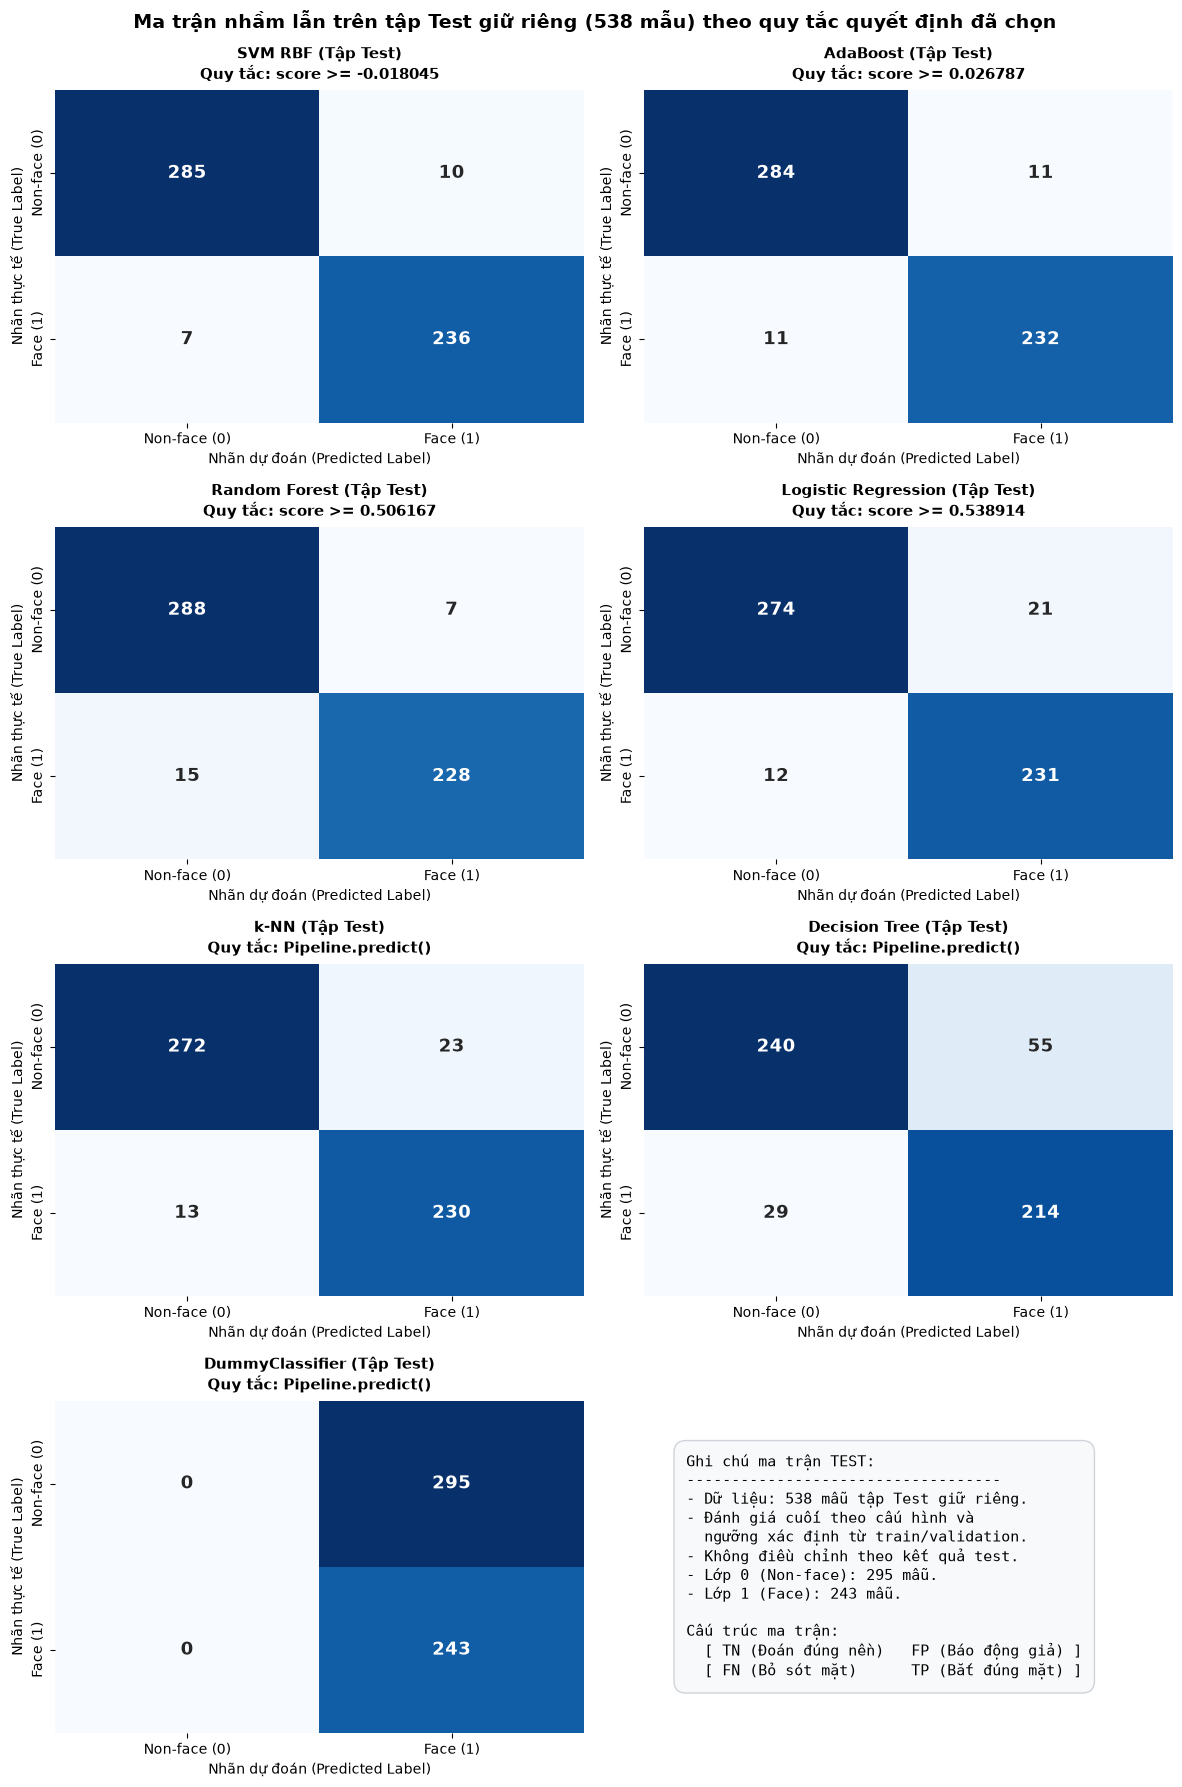

Đã lưu hình ma trận nhầm lẫn Test vào: reports\figures\week6_test_confusion_matrices.png


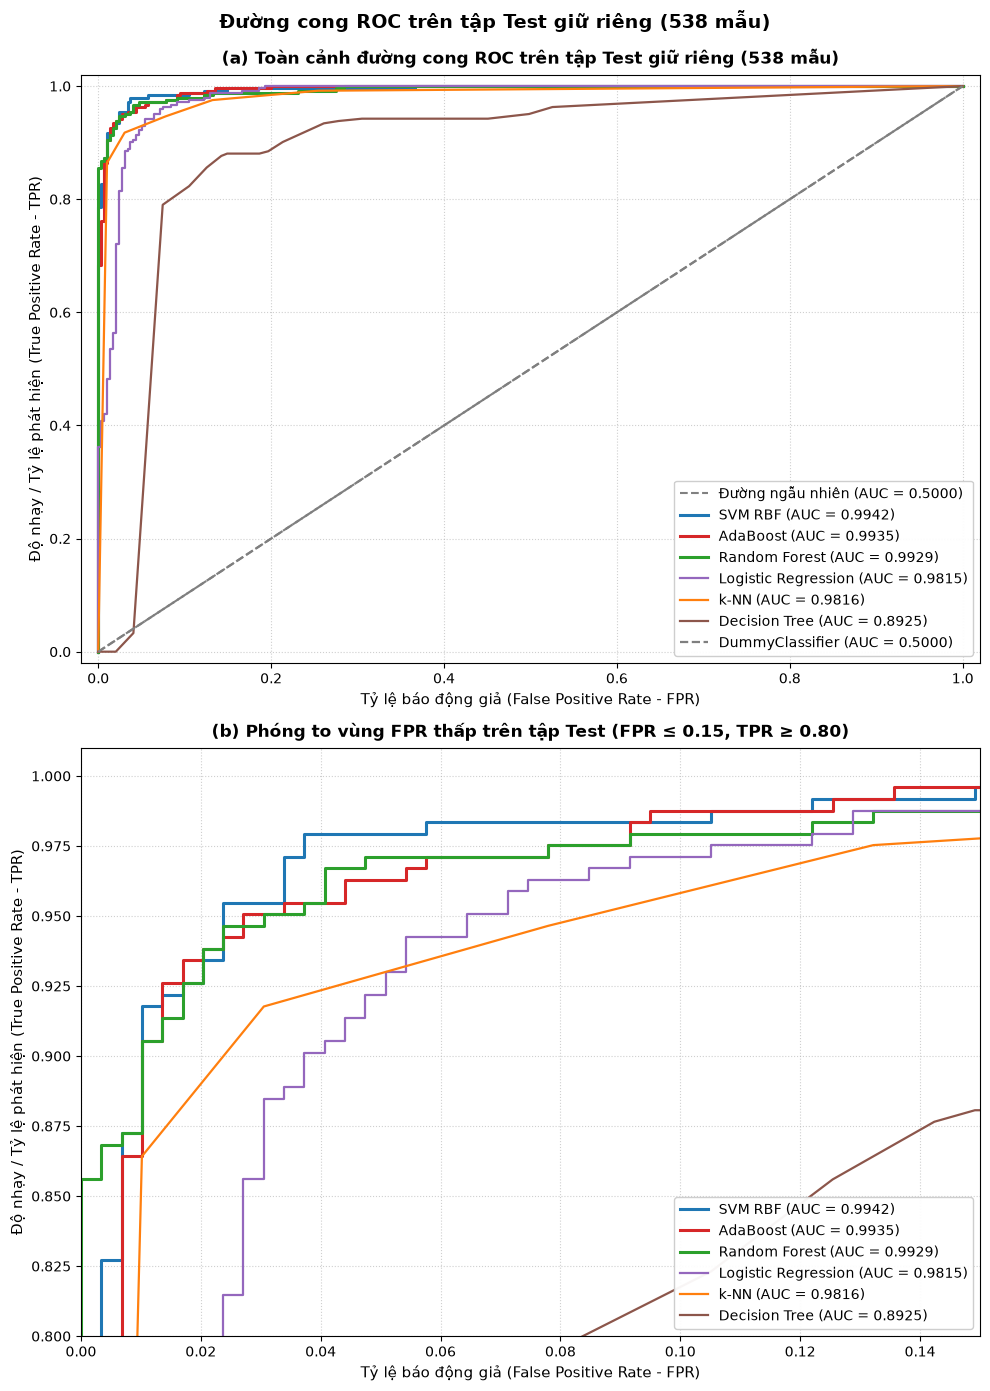

Đã lưu hình đường cong ROC Test vào: reports\figures\week6_test_roc.png


In [20]:
# 1. Vẽ đồ thị ma trận nhầm lẫn trên tập Test (4 hàng x 2 cột A4)
fig, axes = plt.subplots(4, 2, figsize=(12, 18))
axes = axes.flatten()

for idx, m in enumerate(models_order):
    ax = axes[idx]
    sub = df_test_preds[df_test_preds["model"] == m]
    cm = confusion_matrix(sub["y_true"], sub["y_pred_selected"], labels=[0, 1])
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Non-face (0)", "Face (1)"],
                yticklabels=["Non-face (0)", "Face (1)"],
                annot_kws={"size": 13, "weight": "bold"})
    
    rule_str = df_thresh[df_thresh["model"] == m]["threshold_rule"].values[0]
    if "score >=" in rule_str:
        rule_short = "Quy tắc: " + rule_str
    else:
        rule_short = "Quy tắc: Pipeline.predict()"
    ax.set_title(f"{m} (Tập Test)\n{rule_short}", fontsize=11, fontweight="bold", pad=8)
    ax.set_ylabel("Nhãn thực tế (True Label)", fontsize=10)
    ax.set_xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10)

# Ô thứ 8: Hộp chú thích diễn giải
axes[7].axis("off")
summary_test_text = (
    "Ghi chú ma trận TEST:\n"
    "-----------------------------------\n"
    "- Dữ liệu: 538 mẫu tập Test giữ riêng.\n"
    "- Đánh giá cuối theo cấu hình và\n"
    "  ngưỡng xác định từ train/validation.\n"
    "- Không điều chỉnh theo kết quả test.\n"
    "- Lớp 0 (Non-face): 295 mẫu.\n"
    "- Lớp 1 (Face): 243 mẫu.\n\n"
    "Cấu trúc ma trận:\n"
    "  [ TN (Đoán đúng nền)   FP (Báo động giả) ]\n"
    "  [ FN (Bỏ sót mặt)      TP (Bắt đúng mặt) ]"
)
axes[7].text(0.08, 0.5, summary_test_text, fontsize=11, family="monospace", verticalalignment="center",
             bbox=dict(boxstyle="round,pad=0.8", facecolor="#f8f9fa", edgecolor="#ced4da"))

fig.suptitle("Ma trận nhầm lẫn trên tập Test giữ riêng (538 mẫu) theo quy tắc quyết định đã chọn",
             fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
test_cm_path = FIGURES_DIR / "week6_test_confusion_matrices.png"
plt.savefig(test_cm_path, dpi=300)
plt.show()
print(f"Đã lưu hình ma trận nhầm lẫn Test vào: {test_cm_path}")

# 2. Vẽ đồ thị đường cong ROC trên tập Test (2 khung nhìn xếp dọc)
colors = {
    "SVM RBF": "#1f77b4",
    "AdaBoost": "#d62728",
    "Random Forest": "#2ca02c",
    "Logistic Regression": "#9467bd",
    "k-NN": "#ff7f0e",
    "Decision Tree": "#8c564b",
    "DummyClassifier": "#7f7f7f"
}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 14))

# Khung 1: Toàn dải ROC
ax1.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1.5, label="Đường ngẫu nhiên (AUC = 0.5000)")

for m in models_order:
    scores = test_scores_dict[m]
    if len(np.unique(scores)) == 1:
        fpr_t, tpr_t = np.array([0.0, 1.0]), np.array([0.0, 1.0])
        auc_t = 0.5
    else:
        fpr_t, tpr_t, _ = roc_curve(y_test, scores)
        auc_t = roc_auc_score(y_test, scores)
        
    label_text = f"{m} (AUC = {auc_t:.4f})"
    linestyle = "--" if m == "DummyClassifier" else "-"
    lw = 2.2 if m in ["SVM RBF", "AdaBoost", "Random Forest"] else 1.6
    ax1.plot(fpr_t, tpr_t, color=colors[m], lw=lw, linestyle=linestyle, label=label_text)

ax1.set_xlim([-0.02, 1.02])
ax1.set_ylim([-0.02, 1.02])
ax1.set_xlabel("Tỷ lệ báo động giả (False Positive Rate - FPR)", fontsize=11)
ax1.set_ylabel("Độ nhạy / Tỷ lệ phát hiện (True Positive Rate - TPR)", fontsize=11)
ax1.set_title("(a) Toàn cảnh đường cong ROC trên tập Test giữ riêng (538 mẫu)", fontsize=12, fontweight="bold", pad=8)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right", fontsize=10, framealpha=0.95)

# Khung 2: Phóng to vùng FPR thấp
for m in models_order:
    if m == "DummyClassifier":
        continue
    scores = test_scores_dict[m]
    fpr_t, tpr_t, _ = roc_curve(y_test, scores)
    auc_t = roc_auc_score(y_test, scores)
    
    lw = 2.2 if m in ["SVM RBF", "AdaBoost", "Random Forest"] else 1.6
    ax2.plot(fpr_t, tpr_t, color=colors[m], lw=lw, label=f"{m} (AUC = {auc_t:.4f})")

ax2.set_xlim([0.0, 0.15])
ax2.set_ylim([0.80, 1.01])
ax2.set_xlabel("Tỷ lệ báo động giả (False Positive Rate - FPR)", fontsize=11)
ax2.set_ylabel("Độ nhạy / Tỷ lệ phát hiện (True Positive Rate - TPR)", fontsize=11)
ax2.set_title("(b) Phóng to vùng FPR thấp trên tập Test (FPR ≤ 0.15, TPR ≥ 0.80)", fontsize=12, fontweight="bold", pad=8)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower right", fontsize=10, framealpha=0.95)

fig.suptitle("Đường cong ROC trên tập Test giữ riêng (538 mẫu)", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
test_roc_path = FIGURES_DIR / "week6_test_roc.png"
plt.savefig(test_roc_path, dpi=300)
plt.show()
print(f"Đã lưu hình đường cong ROC Test vào: {test_roc_path}")


### 5. Phân tích kết quả thực nghiệm cuối cùng, đối chiếu mục tiêu và giới hạn đồ án

#### 1. Đánh giá mức độ hoàn thành mục tiêu thiết kế ($\text{Recall} \ge 0{,}90$ và $\text{FPR} \le 0{,}05$)
Mục tiêu kỹ thuật đặt ra là mô hình cần đạt đồng thời độ nhạy cao ($\text{Recall} \ge 90\%$) nhằm không bỏ sót khuôn mặt và khống chế tỷ lệ báo động giả thấp ($\text{FPR} \le 5\%$) nhằm hạn chế báo động sai trên ảnh nền:
- **Nhóm đạt đồng thời mục tiêu trên cả Validation và Test:**
  + **SVM (kernel RBF):** Đạt kết quả xuất sắc nhất trên tập Test với $\text{Accuracy} = 0{,}9684$, $\text{Recall} = 0{,}9712$, $\text{FPR} = 0{,}0339$ ($3{,}39\%$), $F_1 = 0{,}9652$ và $\text{ROC-AUC} = 0{,}9942$. Cả chế độ mặc định và chế độ chọn ngưỡng đều đạt đồng thời cả hai tiêu chí trên cả tập Validation và Test.
  + **AdaBoost (Decision Stump):** Thuật toán trọng tâm của đề tài thể hiện rõ tính đánh đổi (*trade-off*) kỹ thuật khi điều chỉnh ngưỡng quyết định:
    * Khi áp dụng ngưỡng tối ưu $\text{score} \ge 0{,}026787$, mô hình chuyển sang trạng thái phân loại thận trọng hơn: số lượng báo động giả $\text{FP}$ giảm từ $13$ xuống $11$ mẫu (tỷ lệ $\text{FPR}$ giảm từ $0{,}0441$ ($4{,}41\%$) xuống còn $0{,}0373$ ($3{,}73\%$)), qua đó thỏa mãn mục tiêu khống chế báo động giả nghiêm ngặt $\text{FPR} \le 5\%$.
    * Đổi lại, số lượng khuôn mặt bị bỏ sót $\text{FN}$ tăng nhẹ từ $9$ lên $11$ mẫu (độ nhạy $\text{Recall}$ giảm từ $0{,}9630$ ($96{,}30\%$) xuống còn $0{,}9547$ ($95{,}47\%$), dù vậy vẫn vượt xa mốc sàn kỹ thuật $\ge 90\%$).
    * Do sự đánh đổi giữa việc giảm $\text{FP}$ và tăng $\text{FN}$, điểm tổng hòa $F_1$ giảm nhẹ từ $0{,}9551$ xuống $0{,}9547$.
    * Phân tích này khẳng định việc hạ $\text{FPR}$ là kết quả của sự đánh đổi có chủ đích theo tiêu chí thiết kế, không phải là sự cải thiện đồng thời mọi chỉ số đo lường.
  + **Random Forest:** Đạt $\text{Recall} = 0{,}9383$ và kiểm soát báo động giả tốt nhất trong các mô hình trên tập Test với $\text{FPR} = 0{,}0237$ ($2{,}37\%$, chỉ có 7 mẫu FP trên 295 mẫu nền), $F_1 = 0{,}9540$ và $\text{ROC-AUC} = 0{,}9929$.
- **Nhóm không đạt đồng thời mục tiêu trên tập Test:**
  + **Logistic Regression:** Trên tập Validation, ngưỡng $\text{score} \ge 0{,}538914$ đã giúp hạ $\text{FPR}$ về đúng $0{,}0500$. Tuy nhiên, khi chuyển sang tập Test độc lập, dù $\text{Recall}$ đạt $0{,}9506$, tỷ lệ báo động giả vẫn ở mức $\text{FPR} = 0{,}0712$ ($7{,}12\% > 5\%$, ghi nhận 21 mẫu FP). Do đó, mô hình tuyến tính **không đạt** mục tiêu khống chế báo động giả trên tập kiểm thử độc lập.
  + **k-NN:** Không tìm được ngưỡng hợp lệ trên tập Validation ($\text{FPR}$ mặc định là $0{,}0577$). Trên tập Test, mô hình đạt $\text{Recall} = 0{,}9465$ nhưng $\text{FPR} = 0{,}0780$ ($7{,}80\% > 5\%$), do đó **không đạt** mục tiêu.
  + **Decision Tree:** Không tìm được ngưỡng hợp lệ trên tập Validation. Trên tập Test, mô hình chỉ đạt $\text{Recall} = 0{,}8807$ ($< 90\%$) và $\text{FPR} = 0{,}1864$ ($18{,}64\% \gg 5\%$), **không đạt cả hai mục tiêu**.
  + **DummyClassifier:** Mô hình cơ sở đoán toàn bộ lớp dương tính, đạt $\text{Recall} = 1{,}0000$ nhưng $\text{FPR} = 1{,}0000$ ($100\%$ báo động giả), đóng vai trò mốc tham chiếu dưới cùng.

#### 2. Tính trung thực khoa học và tính toàn vẹn của tập Test
- Tập test dùng để đánh giá cuối theo cấu hình và ngưỡng đã xác định từ train/validation. Toàn bộ các thông số cấu hình, danh sách ngưỡng tối ưu và quy tắc quyết định đã được đóng băng trong `week6_final_protocol.json` trước khi tiến hành tính toán trên tập Test.
- Sau khi quan sát kết quả trên tập Test, đề tài **tuyệt đối không điều chỉnh lại mô hình, không thay đổi ngưỡng và không đổi thuật toán** nhằm làm đẹp số liệu. Việc Logistic Regression và k-NN không đạt mục tiêu FPR trên tập Test được báo cáo minh bạch và khách quan.

#### 3. Giới hạn phương pháp luận của Đồ án
- Toàn bộ kết quả thực nghiệm trong Tuần 6 phản ánh bài toán **phân loại ô ảnh cắt kích thước cố định $24 \times 24$ điểm ảnh** (phân biệt cửa sổ khuôn mặt và cửa sổ phi khuôn mặt dựa trên $258$ đặc trưng Haar-like).
- Đây **chưa phải là một hệ thống phát hiện khuôn mặt hoàn chỉnh** (Full Face Detector). Trong một hệ thống phát hiện thực tế quét trên ảnh lớn, thuật toán cần kết hợp cơ chế cửa sổ trượt (sliding window) đa tỷ lệ, cấu trúc tầng lọc liên tiếp (cascade architecture) và thuật toán triệt tiêu cực đại cục bộ (Non-Maximum Suppression - NMS) để định vị tọa độ hộp bao (bounding box) của khuôn mặt.
